In [1]:
# %pip install pandas numpy matplotlib scipy statsmodels scikit-learn

# Chicago Crime Pattern Clustering: Progress Version

## Main objective
Identify stable neighborhood crime profiles across Chicago's 77 community areas, based on the mix of crime types reported in each area, and then examine whether those profiles are associated with socioeconomic hardship and with seasonal and temperature patterns.

## How each part supports this objective
1. Clustering finds the crime profiles.
2. The hardship analysis tests whether the profiles relate to neighborhood hardship.
3. The stability analysis checks whether the profiles stay the same from 2020 to 2025.
4. The weather analysis examines how the profiles behave across seasons and temperatures.

## Load datasets

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

crime = pd.read_csv("data/crime_data.csv")
weather = pd.read_csv("data/weather_data.csv")
hardship = pd.read_csv("data/hardship_index.csv")

In [3]:
print("Crime:", crime.shape)
print("Weather:", weather.shape)
print("Hardship:", hardship.shape)

Crime: (1065276, 22)
Weather: (2192, 55)
Hardship: (77, 9)


## Inspect the data
Check columns, data types, and missing values before cleaning.

In [4]:
crime.info()

<class 'pandas.DataFrame'>
RangeIndex: 1065276 entries, 0 to 1065275
Data columns (total 22 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   ID                    1065276 non-null  int64  
 1   Case Number           1065276 non-null  str    
 2   Date                  1065276 non-null  str    
 3   Block                 1065276 non-null  str    
 4   IUCR                  1065276 non-null  str    
 5   Primary Type          1065276 non-null  str    
 6   Description           1065276 non-null  str    
 7   Location Description  1064901 non-null  str    
 8   Arrest                1065276 non-null  bool   
 9   Domestic              1065276 non-null  bool   
 10  Beat                  1065276 non-null  int64  
 11  District              1065276 non-null  int64  
 12  Ward                  1065258 non-null  float64
 13  Community Area        1065190 non-null  float64
 14  FBI Code              1065276 non-null  str  

In [5]:
weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 2192 entries, 0 to 2191
Data columns (total 55 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   STATION  2192 non-null   str    
 1   DATE     2192 non-null   str    
 2   ACMH     0 non-null      float64
 3   ACSH     0 non-null      float64
 4   ADPT     1826 non-null   float64
 5   ASLP     1825 non-null   float64
 6   ASTP     1825 non-null   float64
 7   AWBT     1826 non-null   float64
 8   AWND     2192 non-null   float64
 9   FMTM     0 non-null      float64
 10  PGTM     67 non-null     float64
 11  PRCP     2192 non-null   float64
 12  PSUN     0 non-null      float64
 13  RHAV     1827 non-null   float64
 14  RHMN     1827 non-null   float64
 15  RHMX     1827 non-null   float64
 16  SNOW     2192 non-null   float64
 17  SNWD     2192 non-null   float64
 18  TAVG     0 non-null      float64
 19  TMAX     2192 non-null   int64  
 20  TMIN     2192 non-null   int64  
 21  TSUN     0 non-null      

In [6]:
hardship.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column                                                                                            Non-Null Count  Dtype  
---  ------                                                                                            --------------  -----  
 0   Area Number                                                                                       77 non-null     int64  
 1   Community                                                                                         77 non-null     str    
 2   Crowded Housing Rate (More than one occupant per room)                                            77 non-null     float64
 3   Poverty Rate (Share of households with income below poverty level)                                77 non-null     float64
 4   Unemployment Rate                                                                                 77 non-null     float64
 5   No High School 

## Clean crime data
Convert date, drop rows with no community area, and keep only the columns needed for analysis.

In [7]:
crime["Date"] = pd.to_datetime(crime["Date"])
crime = crime.dropna(subset=["Community Area"])

crime = crime[["Date", "Primary Type", "Arrest", "Domestic", "Community Area", "Latitude", "Longitude"]]
crime["Community Area"] = crime["Community Area"].astype(int)

crime.info()

C:\Users\tisab\AppData\Local\Temp\ipykernel_26292\1534231639.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  crime["Date"] = pd.to_datetime(crime["Date"])


<class 'pandas.DataFrame'>
Index: 1065190 entries, 0 to 1065275
Data columns (total 7 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   Date            1065190 non-null  datetime64[us]
 1   Primary Type    1065190 non-null  str           
 2   Arrest          1065190 non-null  bool          
 3   Domestic        1065190 non-null  bool          
 4   Community Area  1065190 non-null  int64         
 5   Latitude        1056484 non-null  float64       
 6   Longitude       1056484 non-null  float64       
dtypes: bool(2), datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 60.0 MB


In [8]:
crime["Date"] = crime["Date"].dt.normalize()

In [9]:
crime.to_csv("cleaned_crime.csv", index=False)

## Clean weather data
Keep only relevant columns and calculate average temperature manually, since TAVG is empty.

In [10]:
weather["DATE"] = pd.to_datetime(weather["DATE"])
weather["TAVG"] = (weather["TMAX"] + weather["TMIN"]) / 2

weather = weather[["DATE", "TMAX", "TMIN", "TAVG", "PRCP", "SNOW"]]

weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 2192 entries, 0 to 2191
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   DATE    2192 non-null   datetime64[us]
 1   TMAX    2192 non-null   int64         
 2   TMIN    2192 non-null   int64         
 3   TAVG    2192 non-null   float64       
 4   PRCP    2192 non-null   float64       
 5   SNOW    2192 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(2)
memory usage: 102.9 KB


In [11]:
weather[["TMAX", "TMIN", "TAVG", "PRCP", "SNOW"]].describe()

,TMAX,TMIN,TAVG,PRCP,SNOW
count,2192.000000,2192.000000,2192.000000,2192.000000,2192.000000
mean,61.665146,44.857664,53.261405,0.091150,0.084854
std,20.757431,18.533077,19.391204,0.262885,0.487356
min,-1.000000,-10.000000,-4.500000,0.000000,0.000000
25%,44.750000,32.000000,38.000000,0.000000,0.000000
50%,63.000000,45.000000,54.000000,0.000000,0.000000
75%,80.000000,62.000000,70.500000,0.032500,0.000000
max,100.000000,80.000000,87.500000,3.530000,8.400000


In [12]:
weather.to_csv("cleaned_weather.csv", index=False)

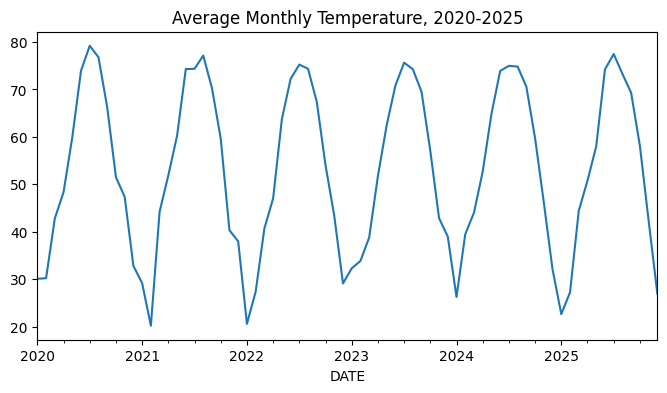

In [13]:
monthly_temp = weather.groupby(weather["DATE"].dt.to_period("M"))["TAVG"].mean()
monthly_temp.plot(figsize=(8,4), title="Average Monthly Temperature, 2020-2025")
plt.show()

## Clean hardship data
Convert Per Capita Income from text to a number and rename columns for easier use later.

In [14]:
hardship["Per Capita Income"] = (
    hardship["Per Capita Income"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(int)
)

hardship = hardship.rename(columns={
    "Area Number": "Community Area",
    "Hardship Index Value": "Hardship Index"
})

hardship.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column                                                                                            Non-Null Count  Dtype  
---  ------                                                                                            --------------  -----  
 0   Community Area                                                                                    77 non-null     int64  
 1   Community                                                                                         77 non-null     str    
 2   Crowded Housing Rate (More than one occupant per room)                                            77 non-null     float64
 3   Poverty Rate (Share of households with income below poverty level)                                77 non-null     float64
 4   Unemployment Rate                                                                                 77 non-null     float64
 5   No High School 

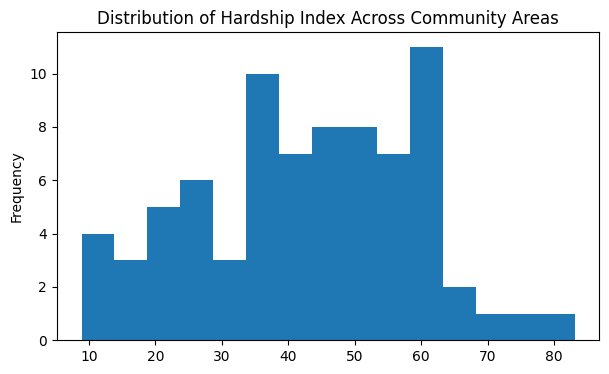

In [15]:
hardship["Hardship Index"].plot(kind="hist", bins=15, figsize=(7,4), title="Distribution of Hardship Index Across Community Areas")
plt.show()

In [16]:
hardship.nlargest(5, "Hardship Index")[["Community", "Hardship Index"]]

,Community,Hardship Index
53,Riverdale,83.1
36,Fuller Park,74.1
25,West Garfield Park,69.3
62,Gage Park,65.9
60,New City,63.6


In [17]:
hardship.to_csv("cleaned_hardship.csv", index=False)

## Aggregate and merge datasets
Collapse crime data to daily counts per community area, then join weather (by date) and hardship (by community area).

In [18]:
daily_crime = (
    crime.groupby(["Community Area", "Date"])
    .size()
    .reset_index(name="Crime Count")
)

merged = daily_crime.merge(weather, left_on="Date", right_on="DATE", how="left")
merged = merged.merge(hardship, on="Community Area", how="left")

merged = merged.drop(columns=["DATE"])

print(merged.shape)
merged.head()

(155307, 16)


,Community Area,Date,Crime Count,TMAX,TMIN,TAVG,PRCP,SNOW,Community,Crowded Housing Rate (More than one occupant per room),Poverty Rate (Share of households with income below poverty level),Unemployment Rate,No High School Diploma Rate (Share of population age 25 and older without a high school diploma),Dependency Rate (Share of population under 18 and over 64 years of age),Per Capita Income,Hardship Index
0,1,2020-01-01,8,42,21,31.5,0.00,0.0,Rogers Park,5.2,16.9,6.2,10.3,26.4,37895,36.5
1,1,2020-01-02,6,48,37,42.5,0.00,0.0,Rogers Park,5.2,16.9,6.2,10.3,26.4,37895,36.5
2,1,2020-01-03,5,41,33,37.0,0.00,0.0,Rogers Park,5.2,16.9,6.2,10.3,26.4,37895,36.5
3,1,2020-01-04,3,33,26,29.5,0.03,0.5,Rogers Park,5.2,16.9,6.2,10.3,26.4,37895,36.5
4,1,2020-01-05,3,42,24,33.0,0.00,0.0,Rogers Park,5.2,16.9,6.2,10.3,26.4,37895,36.5


In [19]:
merged.tail()

,Community Area,Date,Crime Count,TMAX,TMIN,TAVG,PRCP,SNOW,Community,Crowded Housing Rate (More than one occupant per room),Poverty Rate (Share of households with income below poverty level),Unemployment Rate,No High School Diploma Rate (Share of population age 25 and older without a high school diploma),Dependency Rate (Share of population under 18 and over 64 years of age),Per Capita Income,Hardship Index
155302,77,2025-12-27,7,43,38,40.5,0.01,0.0,Edgewater,3.2,14.2,6.7,6.5,26.5,54966,28.1
155303,77,2025-12-28,5,56,22,39.0,0.97,0.0,Edgewater,3.2,14.2,6.7,6.5,26.5,54966,28.1
155304,77,2025-12-29,7,24,14,19.0,0.04,0.9,Edgewater,3.2,14.2,6.7,6.5,26.5,54966,28.1
155305,77,2025-12-30,6,25,10,17.5,0.08,1.6,Edgewater,3.2,14.2,6.7,6.5,26.5,54966,28.1
155306,77,2025-12-31,1,35,16,25.5,0.04,0.0,Edgewater,3.2,14.2,6.7,6.5,26.5,54966,28.1


## Total crime over time
Plot total daily crime across all community areas to check for any obvious trend or anomaly (e.g. pandemic-era disruption).

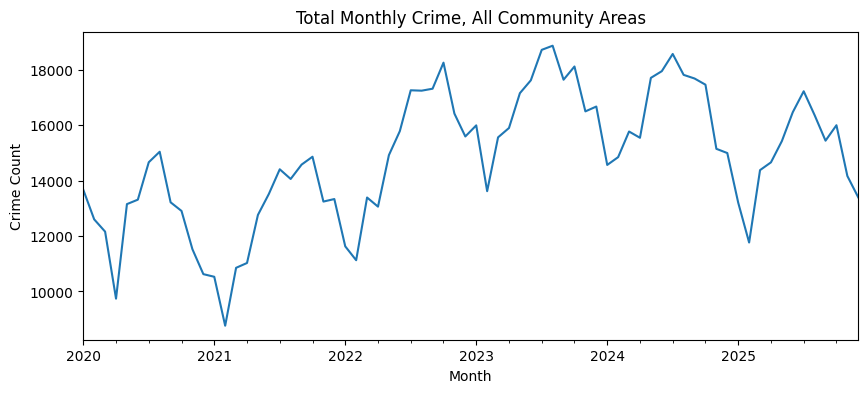

In [20]:
import matplotlib.pyplot as plt

monthly = merged.groupby(merged["Date"].dt.to_period("M"))["Crime Count"].sum()

monthly.plot(figsize=(10, 4))
plt.title("Total Monthly Crime, All Community Areas")
plt.ylabel("Crime Count")
plt.xlabel("Month")
plt.show()

The chart shows a clear yearly pattern: crime consistently drops each winter
(lowest around January-February) and rises each summer (peaking around
July-August), repeating across all six years. There is also a gradual
upward trend in the yearly peaks from 2020 to 2023-2024, followed by a
slight decline into 2025. The lowest point in the entire series falls in
early 2021, which is worth investigating further rather than assuming
it is simply pandemic-related.

## Crime by type
Compare total incidents across the 7 selected crime types.

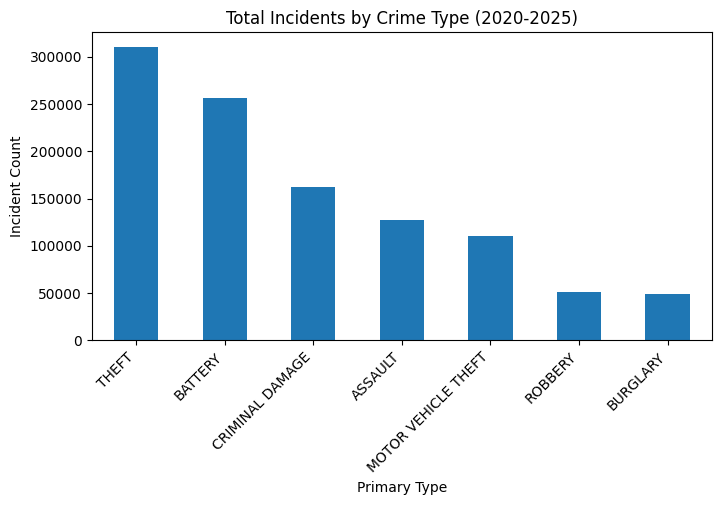

In [21]:
type_counts = crime["Primary Type"].value_counts()

type_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Total Incidents by Crime Type (2020-2025)")
plt.ylabel("Incident Count")
plt.xticks(rotation=45, ha="right")
plt.show()

Theft and Battery are by far the two most common crime types, together
accounting for more than half of all incidents. Criminal Damage and
Assault form a middle tier, while Robbery, Burglary, and Motor Vehicle
Theft are comparatively rare among the 7 selected types. This imbalance
is worth keeping in mind for clustering, since community-area profiles
will likely be driven mostly by Theft and Battery rates unless the
features are scaled appropriately.

## Build clustering features
Create one row per community area with the rate of each crime type. The Hardship Index is merged in for later analysis but is not used as a clustering input.

In [22]:
crime_by_area_type = (
    crime.groupby(["Community Area", "Primary Type"])
    .size()
    .unstack(fill_value=0)
)

features = crime_by_area_type.merge(
    hardship[["Community Area", "Hardship Index"]],
    on="Community Area",
    how="left"
)

features.head()

,Community Area,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT,Hardship Index
0,1,1863,4393,689,2634,1446,742,6624,36.5
1,2,1616,3589,959,2577,1659,659,5015,52.5
2,3,2066,4196,899,2195,1225,616,6983,27.1
3,4,842,1781,615,1344,661,243,3558,23.4
4,5,427,797,519,871,542,188,2375,15.4


## Choose k for baseline clustering
Test a range of cluster counts using silhouette score, based on crime data only (no hardship yet).
This is the baseline model, since it matches what existing Chicago crime projects typically do.

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

crime_types = ["ASSAULT", "BATTERY", "BURGLARY", "CRIMINAL DAMAGE",
               "MOTOR VEHICLE THEFT", "ROBBERY", "THEFT"]

X_baseline = StandardScaler().fit_transform(features[crime_types])

for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_baseline)
    score = silhouette_score(X_baseline, labels)
    print(f"k={k}, silhouette={score:.3f}")

k=2, silhouette=0.594
k=3, silhouette=0.479
k=4, silhouette=0.447
k=5, silhouette=0.478
k=6, silhouette=0.400
k=7, silhouette=0.405


## Fit baseline model (k=3)
Chosen over k=2 despite its slightly higher silhouette score, since k=2 likely
just separates high-crime from low-crime areas without revealing distinct
crime-type archetypes. k=3 balances a reasonable score with more useful detail.

In [24]:
kmeans_baseline = KMeans(n_clusters=3, random_state=42, n_init=10)
features["Baseline Cluster"] = kmeans_baseline.fit_predict(X_baseline)

features.groupby("Baseline Cluster")[crime_types].mean().round(0)

,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT
Baseline Cluster,,,,,,,
0,2107.0,4287.0,800.0,2654.0,1728.0,809.0,4932.0
1,4050.0,8356.0,1453.0,5020.0,3502.0,1814.0,10168.0
2,716.0,1360.0,306.0,972.0,678.0,246.0,1782.0


In [25]:
population = pd.read_csv("data/chicago_health_data.csv", skiprows=[1])
population = population.dropna(subset=["GEOID"])
population.info()


<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Layer          77 non-null     str    
 1   Name           77 non-null     str    
 2   GEOID          77 non-null     int64  
 3   Population     77 non-null     int64  
 4   Longitude      77 non-null     float64
 5   Latitude       77 non-null     float64
 6   HDX_2011-2015  77 non-null     float64
dtypes: float64(3), int64(2), str(2)
memory usage: 6.2 KB


## Note on population data
Population is needed to convert raw crime counts into fair per-capita
rates, since larger community areas naturally have more crimes regardless
of actual danger level. The 2019-2023 Hardship Index table does not
include population, so this single column is borrowed from the earlier
Chicago Health Atlas file (2011-2015 vintage). Only the Population column
is used from this file; the older Hardship Index values in it are ignored.

In [26]:
population.head()

,Layer,Name,GEOID,Population,Longitude,Latitude,HDX_2011-2015
0,Community area,Rogers Park,1,55454,-87.670171,42.009630,64.741637
1,Community area,Norwood Park,10,41069,-87.803451,41.985248,25.624614
2,Community area,Jefferson Park,11,26201,-87.771165,41.978836,47.049867
3,Community area,Forest Glen,12,19579,-87.758358,41.993938,16.568261
4,Community area,North Park,13,17522,-87.723578,41.983651,46.624422


In [27]:
population = population[["GEOID", "Population"]].rename(columns={"GEOID": "Community Area"})
population["Community Area"] = population["Community Area"].astype(int)

features = features.merge(population, on="Community Area", how="left")

for c in crime_types:
    features[c] = features[c] / features["Population"] * 1000

features.head()

,Community Area,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT,Hardship Index,Baseline Cluster,Population
0,1,33.595412,79.218812,12.424712,47.498828,26.075666,13.380459,119.450355,36.5,0,55454
1,2,20.949196,46.526400,12.432103,33.407226,21.506631,8.543020,65.012510,52.5,0,77139
2,3,37.481858,76.124819,16.309869,39.822206,22.224238,11.175617,126.687228,27.1,0,55120
3,4,20.835395,44.071068,15.218252,33.257448,16.356528,6.013065,88.043155,23.4,2,40412
4,5,12.147937,22.674253,14.765292,24.779516,15.419630,5.348506,67.567568,15.4,2,35150


## Re-fit baseline model on corrected rates
The earlier clustering used raw counts before population adjustment, so
that result is no longer valid. Re-checking k and refitting on the
corrected per-capita crime rates.

In [28]:
features = features.drop(columns=["Baseline Cluster"])

X_baseline = StandardScaler().fit_transform(features[crime_types])

for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_baseline)
    score = silhouette_score(X_baseline, labels)
    print(f"k={k}, silhouette={score:.3f}")

k=2, silhouette=0.570
k=3, silhouette=0.502
k=4, silhouette=0.365
k=5, silhouette=0.383
k=6, silhouette=0.367
k=7, silhouette=0.340


## Fit baseline model (k=3, corrected rates)
Same reasoning as before: k=3 chosen over k=2 for more interpretable
crime-type archetypes, now using population-adjusted rates.

In [29]:
kmeans_baseline = KMeans(n_clusters=3, random_state=42, n_init=10)
features["Baseline Cluster"] = kmeans_baseline.fit_predict(X_baseline)

features.groupby("Baseline Cluster")[crime_types].mean().round(1)

,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT
Baseline Cluster,,,,,,,
0,27.8,55.3,13.0,37.9,25.4,10.8,84.9
1,127.7,261.6,33.5,141.3,97.6,53.2,163.5
2,81.1,150.5,24.4,102.0,73.1,27.0,145.9


## Check correlation between crime types
Clusters differ mainly by overall crime level rather than crime-type mix.
Checking whether the 7 crime types are highly correlated with each other,
which would explain why no distinct "type profile" clusters emerged.

In [30]:
features[crime_types].corr().round(2)

,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT
ASSAULT,1.00,0.98,0.82,0.98,0.92,0.85,0.52
BATTERY,0.98,1.00,0.79,0.96,0.89,0.86,0.53
BURGLARY,0.82,0.79,1.00,0.86,0.81,0.72,0.50
CRIMINAL DAMAGE,0.98,0.96,0.86,1.00,0.94,0.82,0.51
MOTOR VEHICLE THEFT,0.92,0.89,0.81,0.94,1.00,0.79,0.58
ROBBERY,0.85,0.86,0.72,0.82,0.79,1.00,0.57
THEFT,0.52,0.53,0.50,0.51,0.58,0.57,1.00


## Visualize crime type correlation
The table above is hard to scan quickly. A heatmap makes the pattern
(most crime types highly correlated, Theft the exception) immediately
visible.

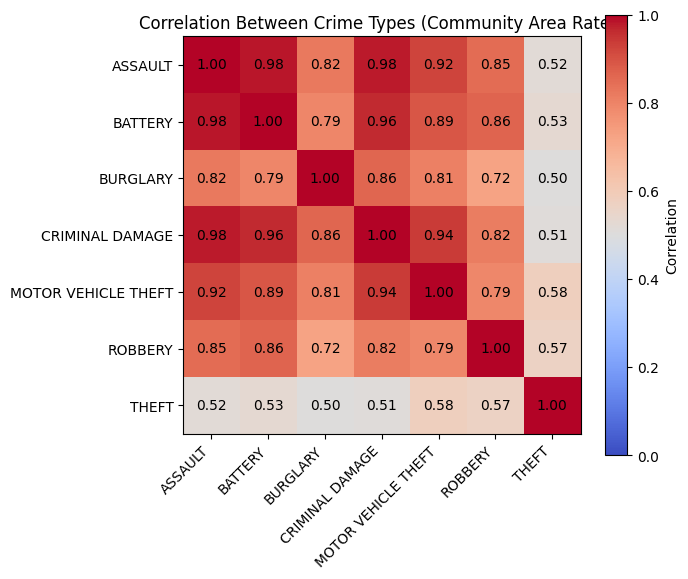

In [31]:
corr_matrix = features[crime_types].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=0, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(crime_types)), crime_types, rotation=45, ha="right")
plt.yticks(range(len(crime_types)), crime_types)

for i in range(len(crime_types)):
    for j in range(len(crime_types)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", color="black")

plt.title("Correlation Between Crime Types (Community Area Rates)")
plt.tight_layout()
plt.show()

The heatmap makes the pattern visually clear: Assault, Battery,
Burglary, Criminal Damage, Motor Vehicle Theft, and Robbery form a
tightly correlated block (dark red, 0.79-0.98), while Theft stands
out as visibly lighter across its entire row and column (0.50-0.58),
confirming it behaves more independently than the other six crime
types.

# Redesigned clustering: addressing sample size feedback

The clustering above used one row per community area (n=77), which
was identified as too small a sample for robust clustering claims.
Below, the analysis is redone using community-area-month observations
instead, substantially increasing the sample size.

In [32]:
crime["Month"] = crime["Date"].dt.to_period("M")

panel = (
    crime.groupby(["Community Area", "Month", "Primary Type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print(panel.shape)
panel.head()

(5544, 9)


Primary Type,Community Area,Month,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT
0,1,2020-01,20,41,9,46,10,14,91
1,1,2020-02,22,44,7,31,9,8,86
2,1,2020-03,17,62,8,35,4,9,59
3,1,2020-04,16,28,10,28,1,10,49
4,1,2020-05,20,60,22,39,7,3,51


## Add hardship, population, and convert to rates
Same approach as the original clustering: merge in Hardship Index and
population, then convert raw counts to per-1,000-residents rates. Applied
here to the community-area-month panel instead of the area-only table.

In [33]:
panel = panel.merge(hardship[["Community Area", "Hardship Index"]], on="Community Area", how="left")
panel = panel.merge(population, on="Community Area", how="left")

for c in crime_types:
    panel[c] = panel[c] / panel["Population"] * 1000

panel.head()

,Community Area,Month,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT,Hardship Index,Population
0,1,2020-01,0.360659,0.739352,0.162297,0.829516,0.180330,0.252461,1.641000,36.5,55454
1,1,2020-02,0.396725,0.793450,0.126231,0.559022,0.162297,0.144264,1.550835,36.5,55454
2,1,2020-03,0.306560,1.118044,0.144264,0.631154,0.072132,0.162297,1.063945,36.5,55454
3,1,2020-04,0.288527,0.504923,0.180330,0.504923,0.018033,0.180330,0.883615,36.5,55454
4,1,2020-05,0.360659,1.081978,0.396725,0.703286,0.126231,0.054099,0.919681,36.5,55454


## Choose k for panel-based clustering
Re-running the same silhouette check as before, now on the much larger
community-area-month dataset instead of the 77-row area-only table.

In [34]:
X_panel = StandardScaler().fit_transform(panel[crime_types])

for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_panel)
    score = silhouette_score(X_panel, labels)
    print(f"k={k}, silhouette={score:.3f}")

k=2, silhouette=0.472
k=3, silhouette=0.340
k=4, silhouette=0.298
k=5, silhouette=0.280
k=6, silhouette=0.289
k=7, silhouette=0.268


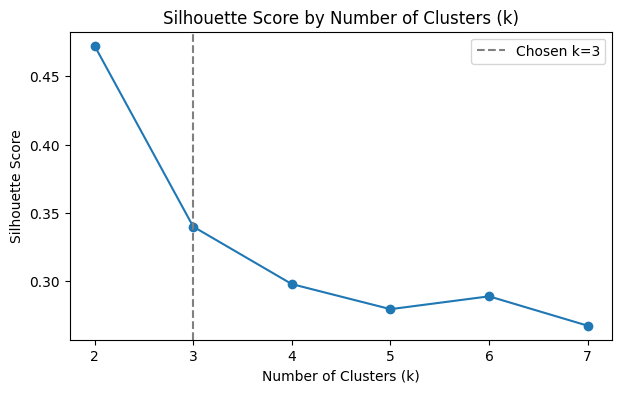

In [35]:
scores = []
for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_panel)
    scores.append(silhouette_score(X_panel, labels))

plt.figure(figsize=(7, 4))
plt.plot(range(2, 8), scores, marker="o")
plt.axvline(x=3, color="gray", linestyle="--", label="Chosen k=3")
plt.title("Silhouette Score by Number of Clusters (k)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.legend()
plt.show()

The silhouette score drops sharply from k=2 to k=3, then flattens with
only minor fluctuation through k=7. Since k=2 likely reflects a simple
high/low crime split rather than distinct crime-type archetypes, k=3
was chosen as the point immediately after the steepest drop, balancing
a reasonable score with more interpretable cluster detail.

## Fit panel-based model (k=3)
Same k=3 choice as the original attempt, for the same interpretability
reasoning, now applied to the larger, more statistically defensible
community-area-month dataset.

In [36]:
kmeans_panel = KMeans(n_clusters=3, random_state=42, n_init=10)
panel["Panel Cluster"] = kmeans_panel.fit_predict(X_panel)

panel.groupby("Panel Cluster")[crime_types].mean().round(2)

,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT
Panel Cluster,,,,,,,
0,0.35,0.70,0.16,0.48,0.30,0.12,1.01
1,1.68,3.26,0.49,2.00,1.43,0.64,2.24
2,0.91,1.76,0.28,1.12,0.82,0.34,2.08


## Visualize cluster crime profiles
The table above shows a compositional shift between clusters (Theft
leads in Clusters 0 and 2, but Battery overtakes it in Cluster 1).
A grouped bar chart makes this crossover visible at a glance.

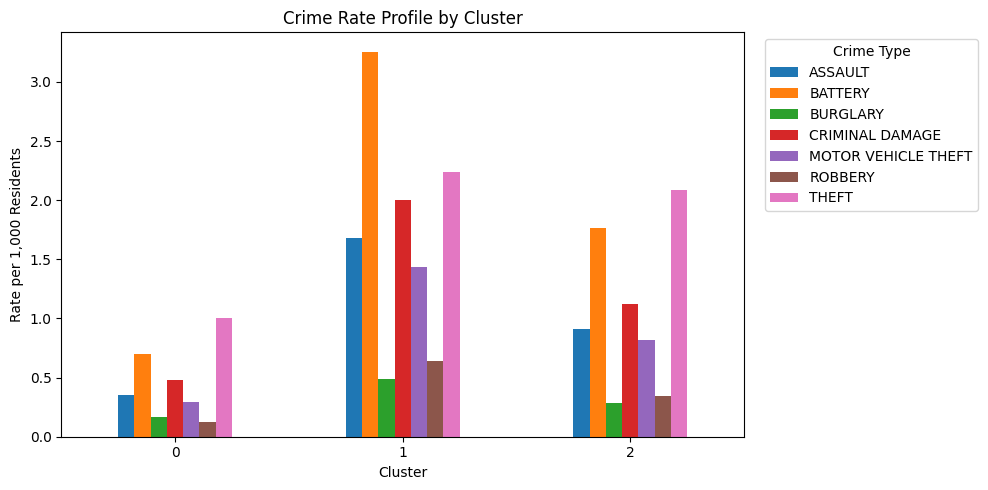

In [37]:
cluster_profile = panel.groupby("Panel Cluster")[crime_types].mean()

cluster_profile.plot(kind="bar", figsize=(10, 5))
plt.title("Crime Rate Profile by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Rate per 1,000 Residents")
plt.xticks(rotation=0)
plt.legend(title="Crime Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Theft is the tallest bar in clusters 0 and 2, and Battery overtakes Theft in cluster 1 (about 3.25 against 2.24 per 1,000 residents). Later analysis shows these clusters mainly separate areas by total crime volume, so this means Battery rises faster than Theft as overall crime rises, not that the cluster shows a distinct crime pattern.

## Cluster stability across years
Using the single fitted model above, check whether each community area
consistently falls into the same cluster across different years, or
shifts over time. This distinguishes persistent structural hotspots
from more transient, time-limited patterns.

In [38]:
panel["Year"] = panel["Month"].dt.year

yearly_cluster = (
    panel.groupby(["Community Area", "Year"])["Panel Cluster"]
    .agg(lambda x: x.mode()[0])
    .unstack()
)

yearly_cluster.head(10)

Year,2020,2021,2022,2023,2024,2025
Community Area,,,,,,
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0
5,0,0,0,0,0,0
6,0,0,0,0,0,0
7,0,0,0,0,0,0
8,0,2,2,2,2,2
9,0,0,0,0,0,0


## Quantify stability
Count how many distinct clusters each community area passed through
across the 6 years. An area with only 1 unique value stayed fully
stable; an area with 3 unique values shifted through every cluster.

In [39]:
stability = yearly_cluster.nunique(axis=1)

print(stability.value_counts().sort_index())
print()
print("Least stable areas:")
print(stability.sort_values(ascending=False).head(10))

1    51
2    25
3     1
Name: count, dtype: int64

Least stable areas:
Community Area
36    3
42    2
31    2
39    2
8     2
35    2
41    2
34    2
33    2
22    2
dtype: int64


## Investigate Community Area 36
The only area that passed through all 3 clusters across 2020-2025.
Checking its year-by-year cluster path and overall crime trend.

In [40]:
print(yearly_cluster.loc[36])

area_36 = panel[panel["Community Area"] == 36]
area_36.groupby("Year")[crime_types].mean().round(2)

Year
2020    0
2021    2
2022    2
2023    1
2024    2
2025    2
Name: 36, dtype: int32


,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT
Year,,,,,,,
2020,0.87,1.47,0.20,1.02,0.34,0.24,1.21
2021,0.78,1.48,0.18,0.88,0.39,0.39,1.10
2022,0.96,1.58,0.17,1.07,1.56,0.24,1.64
2023,1.04,2.02,0.09,1.76,2.47,0.45,1.90
2024,1.11,1.75,0.24,1.58,1.45,0.28,2.07
2025,0.88,1.80,0.27,1.51,1.45,0.17,1.87


## Interpreting Community Area 36's cluster path
The yearly cluster path (0, 2, 2, 1, 2, 2) shows a shift starting in
2021, with a temporary dip to Cluster 1 in 2023. Based on the yearly
averages alone, this could be mistaken for a permanent shift to a
higher-crime profile.

However, the monthly Motor Vehicle Theft chart (below) shows this is
more accurately a transient surge: the rate rose steadily from late
2021, peaked around December 2022 to January 2023, then declined
through 2024 and 2025 back toward its original range. The 2023 dip
to Cluster 1 corresponds to this peak, not a lasting change, which
explains why the area returned to Cluster 2 afterward rather than
climbing further. This distinction, visible only at the monthly
level, illustrates why finer-grained data is necessary to tell
persistent structural hotspots apart from transient, event-driven
ones.

## Visualize Area 36's Motor Vehicle Theft spike
The yearly table shows Motor Vehicle Theft rising sharply starting in
2022. Plotting the monthly values instead of yearly averages shows
the shift more precisely, rather than smoothing it into a single
yearly number.

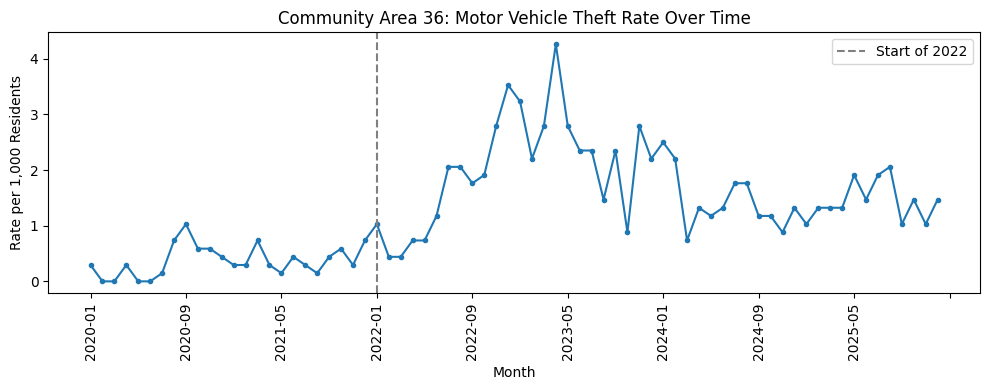

In [41]:
area_36_monthly = panel[panel["Community Area"] == 36].sort_values("Month")

plt.figure(figsize=(10, 4))
plt.plot(area_36_monthly["Month"].astype(str), area_36_monthly["MOTOR VEHICLE THEFT"], marker="o", markersize=3)
plt.axvline(x="2022-01", color="gray", linestyle="--", label="Start of 2022")
plt.title("Community Area 36: Motor Vehicle Theft Rate Over Time")
plt.xlabel("Month")
plt.ylabel("Rate per 1,000 Residents")
plt.xticks(rotation=90)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(12))
plt.legend()
plt.tight_layout()
plt.show()

Monthly data reveals that Community Area 36's Motor Vehicle Theft rate rose steadily beginning in late 2021, peaked sharply in early-to-mid 2023 (exceeding 4 incidents per 1,000 residents), and has since declined through 2024 and 2025, approaching its original level. This pattern is more consistent with a transient, event-driven surge than a permanent structural shift, illustrating why the finer-grained monthly view is necessary to distinguish these two possibilities, exactly the kind of distinction raised in project feedback.

## Summary: cluster stability
Visualize how many community areas are stable vs. shifting, to close
out the clustering analysis before moving to hypothesis testing.

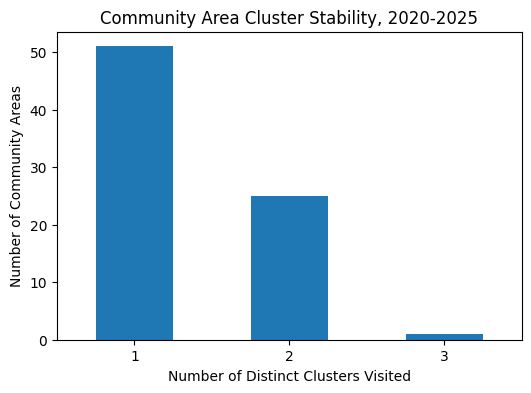

In [42]:
stability.value_counts().sort_index().plot(kind="bar", figsize=(6, 4))
plt.title("Community Area Cluster Stability, 2020-2025")
plt.xlabel("Number of Distinct Clusters Visited")
plt.ylabel("Number of Community Areas")
plt.xticks(rotation=0)
plt.show()

Most community areas (51 of 77) stayed in the same cluster across all six years under the proposal setup, and a small number shifted. The stability checks show this share ranges from 45 to 83 percent depending on the settings, so persistence is real but the exact figure depends on the choices made.

## Visualize clusters geographically
Using each community area's center coordinates to plot its most
common cluster over the full period, giving a rough spatial view of
whether clusters group geographically. This is an approximate
center-point map, not a true boundary map, and does not replace the
spatial autocorrelation analysis noted as future work.

In [43]:
coords = pd.read_csv("data/chicago_health_data.csv", skiprows=[1])
coords = coords.dropna(subset=["GEOID"])
coords = coords[["GEOID", "Longitude", "Latitude"]].rename(columns={"GEOID": "Community Area"})
coords["Community Area"] = coords["Community Area"].astype(int)

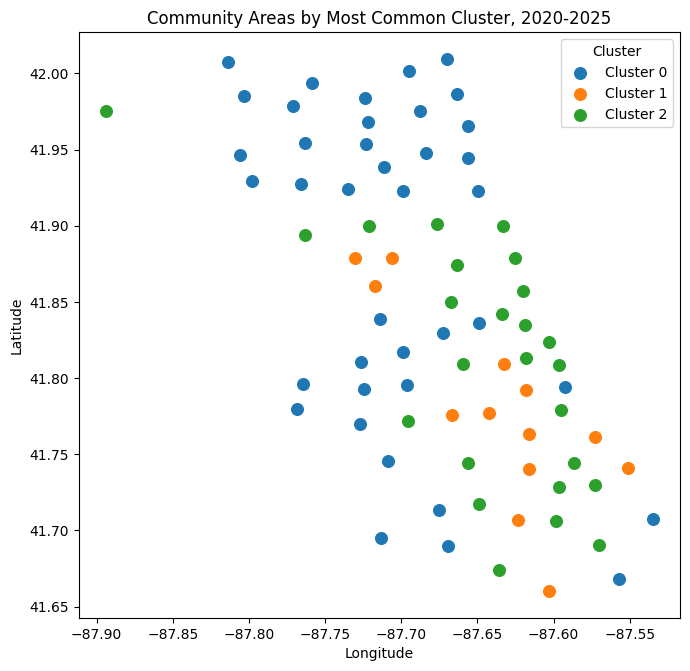

In [44]:
overall_cluster = panel.groupby("Community Area")["Panel Cluster"].agg(lambda x: x.mode()[0]).reset_index()
map_data = overall_cluster.merge(coords, on="Community Area", how="left")

plt.figure(figsize=(7, 8))
for cluster_id in sorted(map_data["Panel Cluster"].unique()):
    subset = map_data[map_data["Panel Cluster"] == cluster_id]
    plt.scatter(subset["Longitude"], subset["Latitude"], label=f"Cluster {cluster_id}", s=70)

plt.title("Community Areas by Most Common Cluster, 2020-2025")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster")
plt.gca().set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

The highest crime cluster (1) lies entirely on the south and west sides, the lowest crime cluster (0) covers most northern and northwest areas plus some far south areas such as Beverly and Mount Greenwood, and the moderate cluster (2) is more mixed, including central and northern areas such as the Loop, Near North Side and West Town.

## List community areas by cluster
The map shows clusters geographically, but does not name which
specific areas fall into each cluster. Listing them directly makes
the results concrete and checkable.

In [45]:
area_cluster_table = overall_cluster.merge(
    hardship[["Community Area", "Community"]], on="Community Area", how="left"
)

for c in sorted(area_cluster_table["Panel Cluster"].unique()):
    names = area_cluster_table[area_cluster_table["Panel Cluster"] == c]["Community"].tolist()
    print(f"Cluster {c} ({len(names)} areas): {', '.join(sorted(names))}")
    print()

Cluster 0 (39 areas): Albany Park, Archer Heights, Ashburn, Avondale, Belmont Cragin, Beverly, Bridgeport, Brighton Park, Clearing, Dunning, East Side, Edgewater, Edison Park, Forest Glen, Gage Park, Garfield Ridge, Hegewisch, Hermosa, Hyde Park, Irving Park, Jefferson Park, Lake View, Lincoln Park, Lincoln Square, Logan Square, Mckinley Park, Montclare, Morgan Park, Mount Greenwood, North Center, North Park, Norwood Park, Portage Park, Rogers Park, South Lawndale, Uptown, West Elsdon, West Lawn, West Ridge

Cluster 1 (13 areas): Chatham, East Garfield Park, Englewood, Fuller Park, Greater Grand Crossing, North Lawndale, Riverdale, Roseland, South Chicago, South Shore, Washington Park, West Englewood, West Garfield Park

Cluster 2 (25 areas): Armour Square, Auburn Gresham, Austin, Avalon Park, Burnside, Calumet Heights, Chicago Lawn, Douglas, Grand Boulevard, Humboldt Park, Kenwood, Loop, Lower West Side, Near North Side, Near South Side, Near West Side, New City, O'Hare, Oakland, Pull

## Build citywide daily dataset
Weather is identical across all community areas on a given day, so it
can only explain day-to-day variation, not area-to-area differences.
Collapsing to one row per day, citywide, keeps the hypothesis tests
valid for the specific comparisons being made (this day vs that day),
rather than mixing in a cross-sectional comparison weather cannot support.


In [46]:
daily_citywide = (
    merged.groupby("Date")
    .agg(
        Total_Crime=("Crime Count", "sum"),
        TMAX=("TMAX", "first"),
        TMIN=("TMIN", "first"),
        TAVG=("TAVG", "first"),
        PRCP=("PRCP", "first"),
    )
    .reset_index()
)

daily_citywide["Weekday"] = daily_citywide["Date"].dt.day_name()
daily_citywide["Is_Weekend"] = daily_citywide["Weekday"].isin(["Saturday", "Sunday"])

print(daily_citywide.shape)
daily_citywide.head()

(2192, 8)


,Date,Total_Crime,TMAX,TMIN,TAVG,PRCP,Weekday,Is_Weekend
0,2020-01-01,592,42,21,31.5,0.00,Wednesday,False
1,2020-01-02,441,48,37,42.5,0.00,Thursday,False
2,2020-01-03,460,41,33,37.0,0.00,Friday,False
3,2020-01-04,469,33,26,29.5,0.03,Saturday,True
4,2020-01-05,442,42,24,33.0,0.00,Sunday,True


## Hypothesis test: weekday vs weekend crime
    
    H0: average daily crime is the same on weekdays and weekends.
    
    H1: average daily crime differs between weekdays and weekends.
    
    Using an independent two-sample t-test, alpha = 0.05.

## First look: simple hypothesis tests on daily crime
The next three tests (weekday versus weekend, temperature correlation, and seasonal ANOVA) were run in the proposal stage. They are kept as an initial exploration, but they compare averages or correlate two variables without accounting for the fact that temperature and season move together, or that crime on one day is related to crime on nearby days. The regression analysis in the section "Comment 5" below addresses both issues and gives the final results for the effects of temperature, weekday and season.

In [47]:
from scipy import stats

weekday_crime = daily_citywide[daily_citywide["Is_Weekend"] == False]["Total_Crime"]
weekend_crime = daily_citywide[daily_citywide["Is_Weekend"] == True]["Total_Crime"]

t_stat, p_value = stats.ttest_ind(weekday_crime, weekend_crime)

print(f"Weekday mean: {weekday_crime.mean():.1f}")
print(f"Weekend mean: {weekend_crime.mean():.1f}")
print(f"t-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.4f}")

Weekday mean: 477.9
Weekend mean: 506.1
t-statistic: -6.772
p-value: 0.0000


Citywide crime is significantly higher on weekends (mean = 506.1) than on weekdays (mean = 477.9), t = -6.77, p < 0.0001. While statistically significant, the practical difference is modest (approximately 6%), which the large sample size (2,192 days) makes easier to detect.

## Visualize weekday vs weekend crime

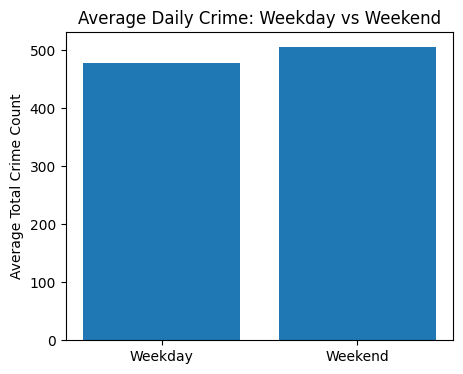

In [48]:
plt.figure(figsize=(5, 4))
plt.bar(["Weekday", "Weekend"], [weekday_crime.mean(), weekend_crime.mean()])
plt.title("Average Daily Crime: Weekday vs Weekend")
plt.ylabel("Average Total Crime Count")
plt.show()

The bar chart shows the weekend increase visually, though the
difference is modest relative to the scale of daily crime counts,
consistent with the statistically significant but practically small
effect size reported earlier.

## Hypothesis test: temperature and crime
    
    H0: no correlation between average daily temperature and total crime. 
    
    H1: a correlation exists between average daily temperature and total crime.
    
    Using Pearson correlation, alpha = 0.05.

In [49]:
corr, p_value = stats.pearsonr(daily_citywide["TAVG"], daily_citywide["Total_Crime"])

print(f"Correlation coefficient: {corr:.3f}")
print(f"p-value: {p_value:.4f}")

Correlation coefficient: 0.509
p-value: 0.0000


Average daily temperature shows a moderate, statistically significant positive correlation with total citywide crime (r = 0.509, p < 0.0001), consistent with findings from Shahmoradi et al. (2025), who similarly identified a positive relationship between temperature and crime in Chicago using a deep learning framework.

## Visualize temperature vs crime
A scatter plot with a trend line, showing the correlation visually
rather than just as a coefficient.

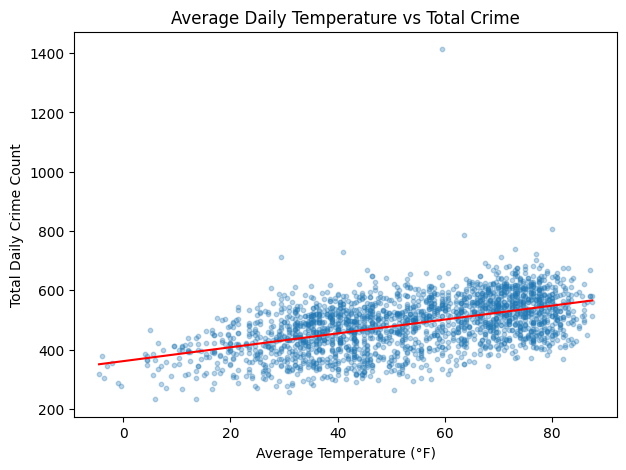

In [50]:
import numpy as np

plt.figure(figsize=(7, 5))
plt.scatter(daily_citywide["TAVG"], daily_citywide["Total_Crime"], alpha=0.3, s=10)

z = np.polyfit(daily_citywide["TAVG"], daily_citywide["Total_Crime"], 1)
trend = np.poly1d(z)
x_range = np.linspace(daily_citywide["TAVG"].min(), daily_citywide["TAVG"].max(), 100)
plt.plot(x_range, trend(x_range), color="red")

plt.title("Average Daily Temperature vs Total Crime")
plt.xlabel("Average Temperature (\u00b0F)")
plt.ylabel("Total Daily Crime Count")
plt.show()

The scatter plot shows a clear upward trend, consistent with the
r = 0.509 correlation calculated earlier. One notable outlier is
visible around 60°F with an unusually high crime count, worth
identifying directly rather than treating as unexplained noise.

In [51]:
daily_citywide[daily_citywide["Total_Crime"] > 1200]

,Date,Total_Crime,TMAX,TMIN,TAVG,PRCP,Weekday,Is_Weekend
151,2020-05-31,1413,69,50,59.5,0.0,Sunday,True


## Note on the temperature-crime outlier
The single extreme outlier (2020-05-31, 1,413 total crimes) coincides
with widespread civil unrest in Chicago following the killing of
George Floyd on May 25, 2020, not with unusual weather (59.5°F was
unremarkable). This is a real, historically explainable event rather
than a data error, but represents a non-weather-driven anomaly that
may influence the temperature-crime correlation.

In [52]:
daily_no_outlier = daily_citywide[daily_citywide["Total_Crime"] <= 1200]
corr_check, p_check = stats.pearsonr(daily_no_outlier["TAVG"], daily_no_outlier["Total_Crime"])
print(f"Correlation without outlier: {corr_check:.3f}, p-value: {p_check:.4f}")

Correlation without outlier: 0.521, p-value: 0.0000


## Robustness check result
Removing the May 31, 2020 outlier changes the correlation only
slightly (r = 0.509 to r = 0.521), confirming the temperature-crime
relationship reflects a genuine pattern across the full dataset
rather than being driven by a single anomalous event.

## Hypothesis test: crime by season
    
    H0: average daily crime is the same across all four seasons.
    
    H1: average daily crime differs across at least one season.
    
    Using a one-way ANOVA, alpha = 0.05.

In [53]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Fall"

daily_citywide["Season"] = daily_citywide["Date"].dt.month.apply(get_season)

groups = [daily_citywide[daily_citywide["Season"] == s]["Total_Crime"] for s in ["Winter", "Spring", "Summer", "Fall"]]
f_stat, p_value = stats.f_oneway(*groups)

print(daily_citywide.groupby("Season")["Total_Crime"].mean().round(1))
print(f"\nF-statistic: {f_stat:.3f}")
print(f"p-value: {p_value:.4f}")

Season
Fall      513.6
Spring    458.5
Summer    534.1
Winter    437.1
Name: Total_Crime, dtype: float64

F-statistic: 177.783
p-value: 0.0000


Total daily crime differs significantly across seasons (F = 177.78, p < 0.0001), with summer averaging the highest crime (534.1) and winter the lowest (437.1), confirming the seasonal pattern observed in the initial exploratory analysis.

| Test | Result | Finding |
|---|---|---|
| Weekday vs. weekend | p < 0.0001 | Weekends significantly higher (~6%) |
| Temperature correlation | r = 0.509, p < 0.0001 | Moderate positive relationship, consistent with published research |
| Seasonal ANOVA | p < 0.0001 | Summer highest, winter lowest, confirming the seasonal EDA finding |


Note: the regression in Comment 5 shows the weekday effect is driven mainly by Saturday being higher, and Monday to Thursday being lower than Friday, with Sunday not clearly different.

## Visualize crime by season

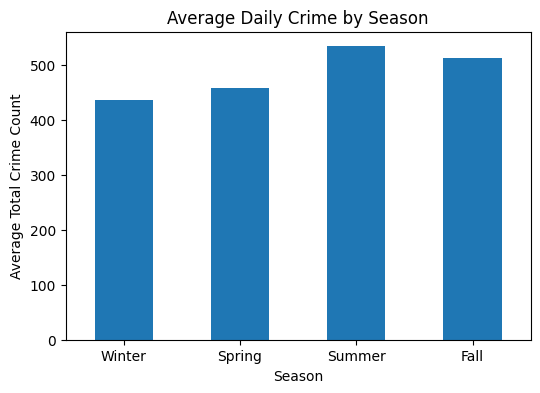

In [54]:
season_order = ["Winter", "Spring", "Summer", "Fall"]
season_means = daily_citywide.groupby("Season")["Total_Crime"].mean().reindex(season_order)

season_means.plot(kind="bar", figsize=(6, 4))
plt.title("Average Daily Crime by Season")
plt.ylabel("Average Total Crime Count")
plt.xticks(rotation=0)
plt.show()

The bar chart confirms the ANOVA result visually: Summer is clearly
highest, Winter clearly lowest, with Spring and Fall sitting between
them in the expected order.

## Outlier and distribution check
Checking for outliers and skewness in crime rate features before
clustering, as required by the methodology.

ASSAULT                1.04
BATTERY                1.10
BURGLARY               1.11
CRIMINAL DAMAGE        0.73
MOTOR VEHICLE THEFT    0.70
ROBBERY                2.07
THEFT                  2.00
dtype: float64


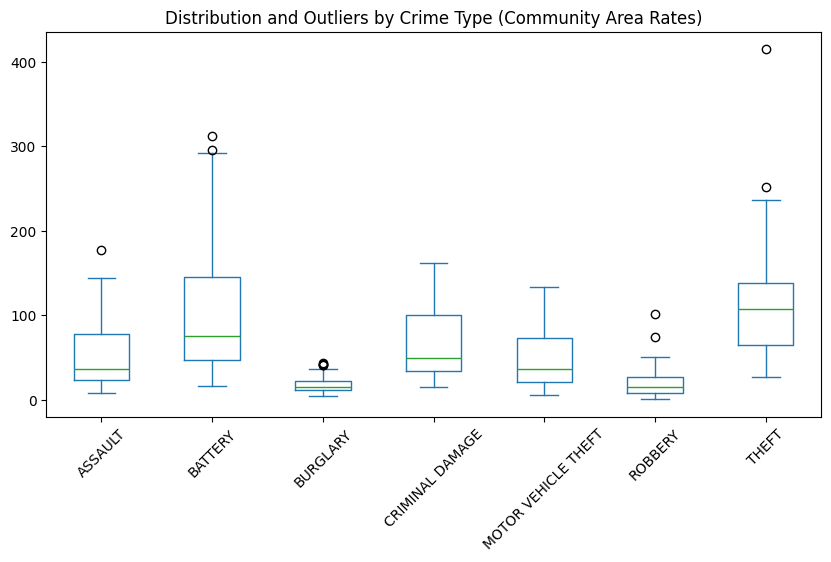

In [55]:
print(features[crime_types].skew().round(2))

features[crime_types].plot(kind="box", figsize=(10, 5), rot=45)
plt.title("Distribution and Outliers by Crime Type (Community Area Rates)")
plt.show()

All seven crime types show positive skewness (ranging from 0.70 for Motor Vehicle Theft to 2.07 for Robbery), reflecting a small number of community areas with unusually elevated crime rates rather than a normal distribution. Theft shows the most extreme individual outlier, with one community area reaching approximately 415 incidents per 1,000 residents against a typical range of 65 to 140.

In [56]:
features.nlargest(3, "THEFT")[["Community Area", "THEFT"]]

,Community Area,THEFT
31,32,414.594843
27,28,251.456125
36,37,236.955669


In [57]:
top_theft = features.nlargest(3, "THEFT")[["Community Area", "THEFT"]]
top_theft.merge(hardship[["Community Area", "Community"]], on="Community Area")

,Community Area,THEFT,Community
0,32,414.594843,Loop
1,28,251.456125,Near West Side
2,37,236.955669,Fuller Park


The three highest-Theft community areas are the Loop (414.6 per 1,000 residents), Near West Side (251.5), and Fuller Park (237.0). The Loop and Near West Side plausibly reflect Chicago's Routine Activity Theory (Cohen & Felson, 1979) prediction that crime opportunity follows population density and activity, not residency: both areas contain major commercial, institutional, or medical districts that draw large daytime populations far exceeding their residential counts, which the per-capita rate does not account for. This represents a direct limitation of population-based crime rates and motivates the exposure-adjusted features discussed in Future Work.

# Progress stage: responses to feedback

## Comment 2: Crime intensity versus crime composition
Do the K-Means clusters describe different kinds of crime, or only different amounts of crime? Compare clusters built on total crime rate with clusters built on the share of each crime type.

### Step 1: Cluster on total crime rate only
Add the seven crime rates into one total rate per area-month and cluster on that alone. Then compare it with the original panel clusters using the adjusted Rand index (ARI), where 1 means identical groupings and 0 means no more similar than chance.

In [58]:
from sklearn.metrics import adjusted_rand_score

panel["Total Rate"] = panel[crime_types].sum(axis=1)

X_total = StandardScaler().fit_transform(panel[["Total Rate"]])
panel["Total Rate Cluster"] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_total)

ari = adjusted_rand_score(panel["Panel Cluster"], panel["Total Rate Cluster"])
print("ARI between the original panel clusters and the total rate clusters:", round(ari, 2))

ARI between the original panel clusters and the total rate clusters: 0.86


### Step 2: Check how the crime mix differs between the original clusters
Convert each crime type into a share of the row's total crime, then compare the average total rate and the main crime shares across the original clusters.

In [59]:
shares = panel[crime_types].div(panel["Total Rate"], axis=0)

summary = shares.copy()
summary["Total Rate"] = panel["Total Rate"]
summary["Panel Cluster"] = panel["Panel Cluster"]
summary.groupby("Panel Cluster")[["Total Rate", "BATTERY", "THEFT", "ASSAULT"]].mean().round(3)

,Total Rate,BATTERY,THEFT,ASSAULT
Panel Cluster,,,,
0,3.116,0.224,0.320,0.113
1,11.738,0.277,0.190,0.143
2,7.325,0.240,0.281,0.125


### Step 3: Cluster on crime mix only
Cluster the area-months using only the crime type shares, ignoring how much crime there is. Silhouette scores show how clear the structure is, and the ARI shows whether these clusters match the original ones.

In [60]:
X_shares = StandardScaler().fit_transform(shares)

for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_shares)
    print(k, round(silhouette_score(X_shares, labels), 2))

panel["Share Cluster"] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_shares)

print("ARI between the original panel clusters and the crime mix clusters:",
      round(adjusted_rand_score(panel["Panel Cluster"], panel["Share Cluster"]), 2))

2 0.22
3 0.2
4 0.2
5 0.2
6 0.2
ARI between the original panel clusters and the crime mix clusters: 0.05


The adjusted Rand index (ARI) shows how similar two clusterings are, where 1 means identical and 0 means no more similar than chance. The original panel clusters and the clusters based on total crime rate alone gave an ARI of 0.86, so the original clusters mostly separate areas by how much crime they have. The clusters based on the share of each crime type gave an ARI of only 0.05 with the original clusters, so they group the data differently. However, their silhouette scores were around 0.2, which means the structure at the month level is weak.

### Step 4: Build crime mix profiles for the 77 areas
Single months are noisy, so use each area's average over the whole period instead. Compute the share of each crime type for each area and check how clear the clusters are for different k.

In [61]:
area_shares = features[crime_types].div(features[crime_types].sum(axis=1), axis=0)

for k in range(2, 6):
    labels = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(area_shares)
    print(k, round(silhouette_score(area_shares, labels), 3))

2 0.467
3 0.404
4 0.348
5 0.338


### Step 5: Describe the three profiles
Fit k=3 and look at the average crime mix of each group. Compare the shares, not the cluster numbers, because the numbers can come out in a different order.

In [62]:
features["Mix Cluster"] = KMeans(n_clusters=3, random_state=42, n_init=20).fit_predict(area_shares)

profile = area_shares.copy()
profile["Mix Cluster"] = features["Mix Cluster"]
profile.groupby("Mix Cluster")[crime_types].mean().round(3)

,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT
Mix Cluster,,,,,,,
0,0.140,0.272,0.042,0.172,0.117,0.051,0.206
1,0.082,0.169,0.052,0.122,0.089,0.041,0.446
2,0.113,0.220,0.056,0.158,0.103,0.036,0.313


### Step 6: Name the areas in each profile
List the community areas in each group to check whether the profiles match recognizable parts of the city.

In [63]:
names = features.merge(hardship[["Community Area", "Community"]], on="Community Area")
for c in sorted(names["Mix Cluster"].unique()):
    print(c, ", ".join(names[names["Mix Cluster"] == c]["Community"]), "\n")

0 Hermosa, Humboldt Park, Austin, West Garfield Park, East Garfield Park, North Lawndale, South Lawndale, Oakland, Fuller Park, Grand Boulevard, Washington Park, Woodlawn, South Shore, Chatham, Avalon Park, South Chicago, Burnside, Calumet Heights, Roseland, South Deering, East Side, West Pullman, Riverdale, Hegewisch, Brighton Park, New City, West Elsdon, Gage Park, Chicago Lawn, West Englewood, Englewood, Greater Grand Crossing, Ashburn, Auburn Gresham, Washington Heights 

1 Lincoln Square, North Center, Lake View, Lincoln Park, Near North Side, Avondale, Logan Square, West Town, Near West Side, Loop, Hyde Park, O'Hare, Edgewater 

2 Rogers Park, West Ridge, Uptown, Edison Park, Norwood Park, Jefferson Park, Forest Glen, North Park, Albany Park, Portage Park, Irving Park, Dunning, Montclare, Belmont Cragin, Lower West Side, Near South Side, Armour Square, Douglas, Kenwood, Pullman, Garfield Ridge, Archer Heights, Mckinley Park, Bridgeport, Clearing, West Lawn, Beverly, Mount Greenwo

At the area level the structure is clearer (silhouette about 0.4 for k=3). The three groups look like a theft heavy profile (mostly downtown, lakefront and north side areas), a violence heavy profile (mostly south and west side areas), and a mixed profile. The violence heavy group also has a higher total crime rate, so mix and volume are related at the area level, but the profiles still differ in what kind of crime they have.

### How much crime versus what kind of crime

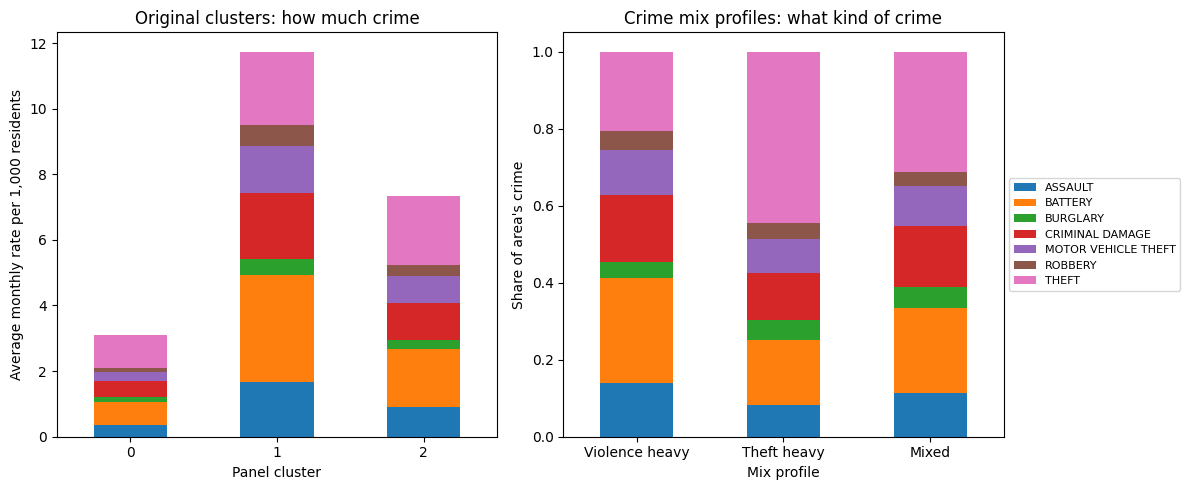

In [64]:
import matplotlib.pyplot as plt

# Check these names against your Step 5 table: 0 had the highest Battery share, 1 the highest Theft share
mix_names = {0: "Violence heavy", 1: "Theft heavy", 2: "Mixed"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

orig = panel.groupby("Panel Cluster")[crime_types].mean()
orig.plot(kind="bar", stacked=True, ax=axes[0], legend=False)
axes[0].set_title("Original clusters: how much crime")
axes[0].set_xlabel("Panel cluster")
axes[0].set_ylabel("Average monthly rate per 1,000 residents")

mix = profile.groupby("Mix Cluster")[crime_types].mean()
mix.index = [mix_names[i] for i in mix.index]
mix.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Crime mix profiles: what kind of crime")
axes[1].set_xlabel("Mix profile")
axes[1].set_ylabel("Share of area's crime")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)

axes[0].tick_params(axis="x", rotation=0)
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

The original clusters differ mainly in how much crime they have, with average rates rising from about 3 to 12 per 1,000 residents across clusters, while the crime type proportions change only modestly. The crime mix profiles all have the same total height because they show shares, so the differences are in the proportions: the theft heavy profile has a much larger share of Theft, and the violence heavy profile has larger shares of Battery and Assault. This supports the idea that the original clusters describe crime volume, while the mix profiles describe crime type.

### Where the crime mix profiles are located

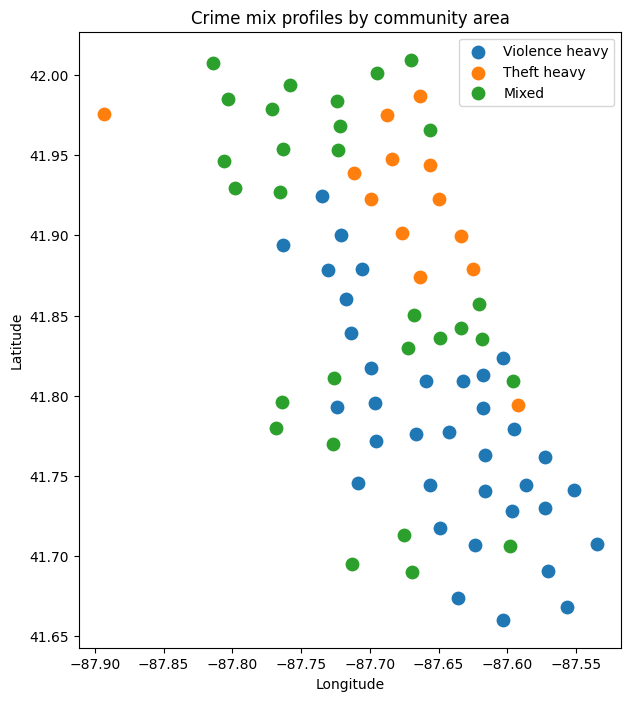

In [65]:
map_mix = features.merge(coords, on="Community Area", how="left")

plt.figure(figsize=(7, 8))
for c, label in mix_names.items():
    d = map_mix[map_mix["Mix Cluster"] == c]
    plt.scatter(d["Longitude"], d["Latitude"], s=80, label=label)
plt.legend()
plt.title("Crime mix profiles by community area")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

The crime mix profiles show a clear geographic pattern even though location was not used in the clustering. The violence heavy profile is concentrated in the south and west of the city, the theft heavy profile forms a band through the central and lakefront areas, and the mixed profile is found mostly in the north and northwest. The pattern is not perfectly clean, since mixed and violence heavy areas overlap in parts of the south, but it suggests the profiles reflect real differences between parts of the city.

### Total crime rate against Theft share

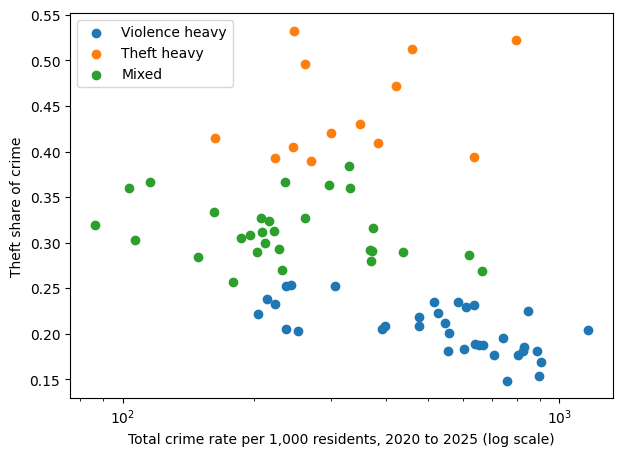

In [66]:
plt.figure(figsize=(7, 5))
for c, label in mix_names.items():
    m = features["Mix Cluster"] == c
    plt.scatter(features.loc[m, crime_types].sum(axis=1), area_shares.loc[m, "THEFT"], label=label)
plt.xscale("log")
plt.xlabel("Total crime rate per 1,000 residents, 2020 to 2025 (log scale)")
plt.ylabel("Theft share of crime")
plt.legend()
plt.show()

Areas with a higher total crime rate tend to have a lower share of Theft, so crime mix and crime volume are related at the area level. The violence heavy profile sits at high total rates with a low Theft share, while the mixed profile sits at lower total rates. However, the theft heavy profile appears across a wide range of total rates, including some of the highest, so crime mix is not simply a restatement of crime volume. The very high Theft share at a high total rate probably reflects the Loop, whose rate is inflated by its large daytime population.

In [67]:
overall = area_shares[crime_types].mean()
diff = profile.groupby("Mix Cluster")[crime_types].mean() - overall
diff.index = [mix_names[i] for i in diff.index]
diff.round(3)

,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,ROBBERY,THEFT
Violence heavy,0.020,0.037,-0.007,0.014,0.010,0.007,-0.081
Theft heavy,-0.039,-0.066,0.003,-0.037,-0.018,-0.003,0.159
Mixed,-0.007,-0.015,0.007,-0.000,-0.004,-0.008,0.027


## Comment 3: Hardship as an outside variable
Hardship was not used as an input to any clustering. The crime profiles were found from crime data alone. Here we test whether those profiles are associated with the Hardship Index.

### Step 1: Is hardship related to each crime type?
Spearman correlation between the Hardship Index and each crime type's rate across the 77 areas. Spearman is used because the data is skewed. A value near 1 means higher hardship goes with higher crime, and near 0 means no relationship.

In [68]:
from scipy import stats

rows = []
for c in crime_types:
    rho, p = stats.spearmanr(features["Hardship Index"], features[c])
    rows.append((c, round(rho, 2), round(p, 4)))

rho, p = stats.spearmanr(features["Hardship Index"], features[crime_types].sum(axis=1))
rows.append(("TOTAL", round(rho, 2), round(p, 4)))

pd.DataFrame(rows, columns=["Crime type", "Spearman rho", "p-value"])

,Crime type,Spearman rho,p-value
0,ASSAULT,0.60,0.0000
1,BATTERY,0.60,0.0000
2,BURGLARY,0.28,0.0136
3,CRIMINAL DAMAGE,0.55,0.0000
4,MOTOR VEHICLE THEFT,0.46,0.0000
5,ROBBERY,0.53,0.0000
6,THEFT,0.02,0.8302
7,TOTAL,0.43,0.0001


### Step 2: Does hardship differ across the original clusters?
Compare hardship across the original rate based clusters, using each area's most common cluster. The Kruskal Wallis test checks whether the groups differ, without assuming a normal distribution.

In [69]:
area_rate_cluster = overall_cluster.merge(hardship[["Community Area", "Hardship Index"]], on="Community Area")

print(area_rate_cluster.groupby("Panel Cluster")["Hardship Index"].agg(["count", "median"]).round(1))

groups = [g["Hardship Index"] for _, g in area_rate_cluster.groupby("Panel Cluster")]
h, p = stats.kruskal(*groups)
print(f"Kruskal Wallis: H = {h:.2f}, p = {p:.6f}")

               count  median
Panel Cluster               
0                 39    36.5
1                 13    59.6
2                 25    47.1
Kruskal Wallis: H = 19.61, p = 0.000055


### Step 3: Does hardship differ across the crime mix profiles?
The same test for the three crime mix profiles from comment 2.

In [70]:
print(features.groupby("Mix Cluster")["Hardship Index"].agg(["count", "median"]).round(1))

groups = [g["Hardship Index"] for _, g in features.groupby("Mix Cluster")]
h, p = stats.kruskal(*groups)
print(f"Kruskal Wallis: H = {h:.2f}, p = {p:.8f}")

             count  median
Mix Cluster               
0               35    54.3
1               13    19.5
2               29    37.8
Kruskal Wallis: H = 46.22, p = 0.00000000


### Step 4: Which matters more for hardship, how much crime or what kind of crime?
Measure intensity as the log of the total crime rate and composition as the log ratio of (Battery + Assault) to Theft. A log ratio is used because crime shares always add up to 100%. Then compare how much of the variation in hardship each one explains.

In [71]:
import numpy as np
import statsmodels.api as sm

features["Log Total Rate"] = np.log(features[crime_types].sum(axis=1))
features["Log Violence/Theft"] = np.log((features["BATTERY"] + features["ASSAULT"]) / features["THEFT"])

for col in ["Log Total Rate", "Log Violence/Theft"]:
    rho, p = stats.spearmanr(features["Hardship Index"], features[col])
    print(col, "Spearman rho:", round(rho, 2))

for name, cols in [("Intensity only", ["Log Total Rate"]),
                   ("Mix only", ["Log Violence/Theft"]),
                   ("Both", ["Log Total Rate", "Log Violence/Theft"])]:
    X = sm.add_constant((features[cols] - features[cols].mean()) / features[cols].std())
    model = sm.OLS(features["Hardship Index"], X).fit(cov_type="HC3")
    print(name, "R-squared:", round(model.rsquared, 2), model.pvalues.round(3).to_dict())

Log Total Rate Spearman rho: 0.43
Log Violence/Theft Spearman rho: 0.82
Intensity only R-squared: 0.19 {'const': 0.0, 'Log Total Rate': 0.0}
Mix only R-squared: 0.72 {'const': 0.0, 'Log Violence/Theft': 0.0}
Both R-squared: 0.72 {'const': 0.0, 'Log Total Rate': 0.845, 'Log Violence/Theft': 0.0}


### Visual: Hardship against crime intensity, crime mix, and mix profile
Left: hardship against total crime rate. Middle: hardship against the violence to theft log ratio. Right: hardship in each crime mix profile.

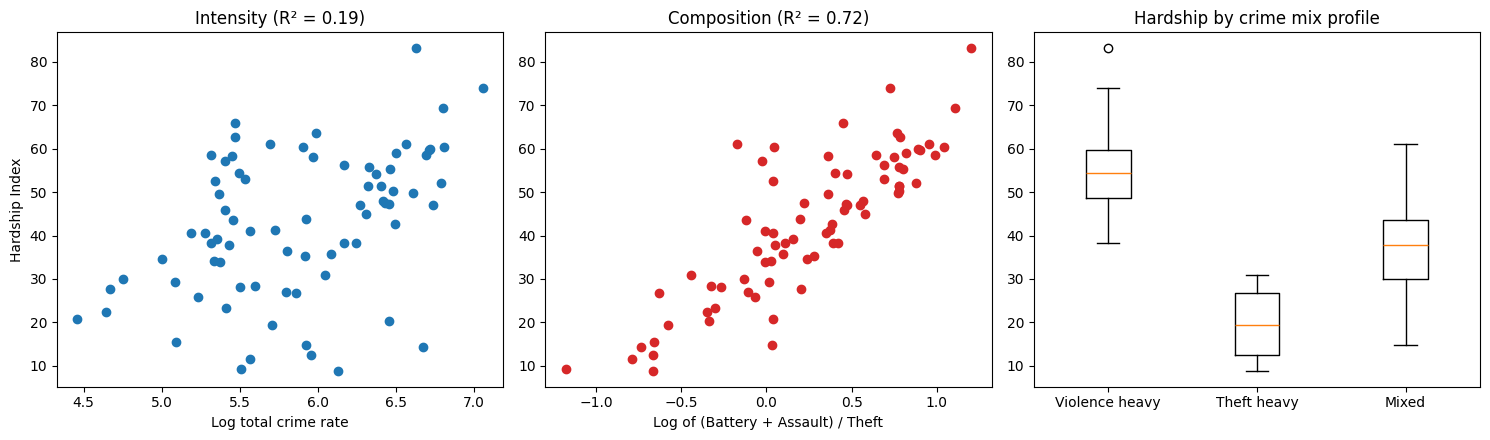

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].scatter(features["Log Total Rate"], features["Hardship Index"])
axes[0].set_xlabel("Log total crime rate")
axes[0].set_ylabel("Hardship Index")
axes[0].set_title("Intensity (R² = 0.19)")

axes[1].scatter(features["Log Violence/Theft"], features["Hardship Index"], color="tab:red")
axes[1].set_xlabel("Log of (Battery + Assault) / Theft")
axes[1].set_title("Composition (R² = 0.72)")

data = [features.loc[features["Mix Cluster"] == c, "Hardship Index"] for c in [0, 1, 2]]
axes[2].boxplot(data)
axes[2].set_xticks([1, 2, 3])
axes[2].set_xticklabels([mix_names[c] for c in [0, 1, 2]])
axes[2].set_title("Hardship by crime mix profile")

plt.tight_layout()
plt.show()

### Interpretation of the hardship results
Hardship was positively related to most crime types (Spearman rho between 0.28 and 0.60) but not to Theft (rho = 0.02). Hardship differed across both sets of clusters, but much more strongly across the crime mix profiles (Kruskal Wallis H = 46.22) than across the original clusters (H = 19.61). Crime composition explained far more of the variation in hardship than crime volume did (R-squared 0.72 against 0.19), and once composition was included, total crime rate added nothing. This means that the kind of crime in a neighborhood is more closely tied to hardship than the amount of crime. These are associations between areas and do not show that hardship causes a particular crime mix. The Hardship Index covers 2019 to 2023 while the crime data covers 2020 to 2025.

## Comment 4: Validating cluster stability
The proposal reported that 51 of 77 community areas (66 percent) stayed in the same cluster every year. This result depends on choices made: k = 3, standard scaling, and all seven crime types. Here the stability calculation is repeated while changing one choice at a time.

### Step 1: Turn the stability calculation into a function
The function fits one K-Means model on all area-months, finds each area's most common cluster per year, and counts the areas that never change cluster. This is the same calculation as before, so it can be repeated with different settings.

In [73]:
import numpy as np
from sklearn.preprocessing import StandardScaler, RobustScaler

def stability_check(df, features, scaler, k, log_transform=False, seed=42):
    X = df[features].values.astype(float)
    if log_transform:
        X = np.log1p(X * 10)
    X = scaler.fit_transform(X)
    labels = KMeans(n_clusters=k, random_state=seed, n_init=10).fit_predict(X)

    temp = df[["Community Area", "Year"]].copy()
    temp["Cluster"] = labels
    yearly = temp.groupby(["Community Area", "Year"])["Cluster"].agg(lambda x: x.mode()[0]).unstack()

    stable = (yearly.nunique(axis=1) == 1).sum()
    return stable, len(yearly)

results = []

def record(name, stable, total):
    results.append((name, stable, total, round(100 * stable / total)))
    print(name, ":", stable, "of", total, "areas stable (", round(100 * stable / total), "percent )")

### Step 2: Check that the function reproduces the proposal result
The baseline should give 51 of 77 areas.

In [74]:
stable, total = stability_check(panel, crime_types, StandardScaler(), 3)
record("Proposal setup (k=3, standard scaling, 7 crime types)", stable, total)

Proposal setup (k=3, standard scaling, 7 crime types) : 51 of 77 areas stable ( 66 percent )


### Step 3: Change the number of clusters
More clusters create more boundaries for an area to cross, so stability is expected to fall as k rises. This shows how much.

In [75]:
for k in [2, 4, 5, 6]:
    stable, total = stability_check(panel, crime_types, StandardScaler(), k)
    record(f"k = {k}", stable, total)

k = 2 : 64 of 77 areas stable ( 83 percent )
k = 4 : 42 of 77 areas stable ( 55 percent )
k = 5 : 41 of 77 areas stable ( 53 percent )
k = 6 : 35 of 77 areas stable ( 45 percent )


### Step 4: Change the feature scaling
Standard scaling was used in the proposal. Robust scaling is less affected by extreme values, and a log transform reduces skewness before scaling.

In [76]:
stable, total = stability_check(panel, crime_types, RobustScaler(), 3)
record("Robust scaling", stable, total)

stable, total = stability_check(panel, crime_types, StandardScaler(), 3, log_transform=True)
record("Log transform, then standard scaling", stable, total)

Robust scaling : 51 of 77 areas stable ( 66 percent )
Log transform, then standard scaling : 38 of 77 areas stable ( 49 percent )


### Step 5: Change the crime categories used
Repeat the check with different groups of crime types, because most crime types are highly correlated and Theft behaves differently from the others.

In [77]:
subsets = {
    "Without Theft": [c for c in crime_types if c != "THEFT"],
    "Violent crimes only (Assault, Battery, Robbery)": ["ASSAULT", "BATTERY", "ROBBERY"],
    "Property crimes only": ["BURGLARY", "CRIMINAL DAMAGE", "MOTOR VEHICLE THEFT", "THEFT"],
    "Without Theft and Robbery": [c for c in crime_types if c not in ("THEFT", "ROBBERY")],
}

for name, feats in subsets.items():
    stable, total = stability_check(panel, feats, StandardScaler(), 3)
    record(name, stable, total)

Without Theft : 58 of 77 areas stable ( 75 percent )
Violent crimes only (Assault, Battery, Robbery) : 61 of 77 areas stable ( 79 percent )
Property crimes only : 35 of 77 areas stable ( 45 percent )
Without Theft and Robbery : 54 of 77 areas stable ( 70 percent )


### Step 6: Remove the Loop
The Loop has an extreme Theft rate because its daytime population is not in the population count. Check that the result does not depend on this one area.

In [78]:
panel_no_loop = panel[panel["Community Area"] != 32]
stable, total = stability_check(panel_no_loop, crime_types, StandardScaler(), 3)
record("Without the Loop", stable, total)

Without the Loop : 44 of 76 areas stable ( 58 percent )


### Step 7: Change the random seed
K-Means starts from random points, so different seeds can give slightly different clusters. Repeat the baseline with ten seeds.

In [79]:
seed_counts = []
for seed in range(10):
    stable, total = stability_check(panel, crime_types, StandardScaler(), 3, seed=seed)
    seed_counts.append(int(stable))

print("Stable areas across 10 seeds:", seed_counts)
print("Range:", min(seed_counts), "to", max(seed_counts), "of 77")

Stable areas across 10 seeds: [55, 50, 51, 55, 49, 50, 50, 50, 49, 51]
Range: 49 to 55 of 77


### Step 8: Summary table and chart

,Variation,Stable areas,Total areas,Percent stable
0,"Proposal setup (k=3, standard scaling, 7 crime...",51,77,66
1,k = 2,64,77,83
2,k = 4,42,77,55
3,k = 5,41,77,53
4,k = 6,35,77,45
5,Robust scaling,51,77,66
6,"Log transform, then standard scaling",38,77,49
7,Without Theft,58,77,75
8,"Violent crimes only (Assault, Battery, Robbery)",61,77,79
9,Property crimes only,35,77,45


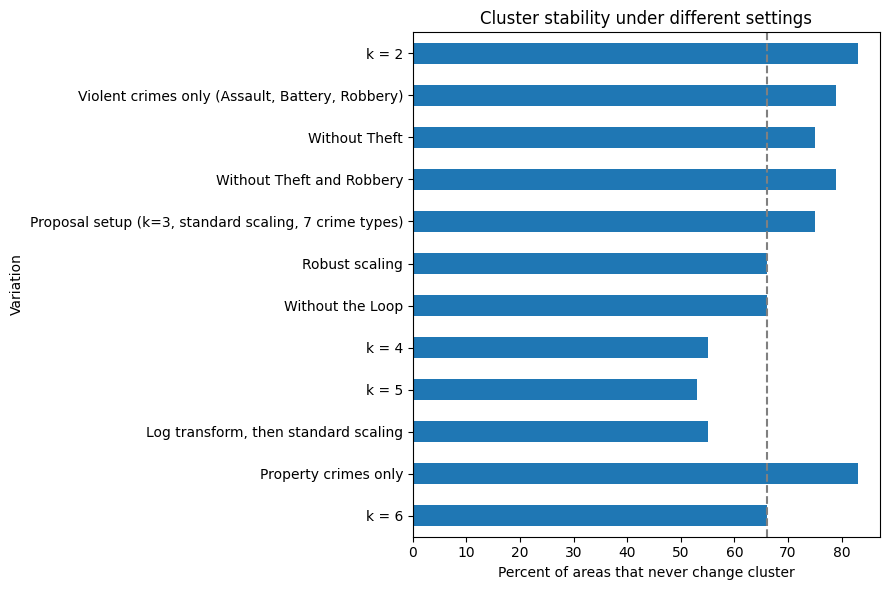

In [80]:
stability_table = pd.DataFrame(results, columns=["Variation", "Stable areas", "Total areas", "Percent stable"])
display(stability_table)

stability_table.set_index("Variation")["Percent stable"].plot(kind="barh", figsize=(9, 6))
stability_table.sort_values("Percent stable").set_index("Variation")["Percent stable"].plot(kind="barh", figsize=(9, 6))
plt.axvline(66, color="gray", linestyle="--")
plt.xlabel("Percent of areas that never change cluster")
plt.title("Cluster stability under different settings")
plt.tight_layout()
plt.show()

### Interpretation of the stability checks
The share of community areas that stay in one cluster from 2020 to 2025 depends on the modeling choices. It falls steadily as the number of clusters increases (83 percent at k=2 to 45 percent at k=6), drops to 49 percent with a log transform, and ranges from 45 percent (property crimes only) to 79 percent (violent crimes only) across crime categories. Random seeds changed the count only slightly (49 to 55 of 77 areas). The proposal result of 66 percent should therefore be reported as a result for one specification and not as a fixed property of Chicago's neighborhoods. A majority of areas stay in the same cluster in most setups, which suggests that crime profiles are fairly persistent, but the exact proportion is sensitive to the choices made. These checks are a sensitivity analysis and not a formal test of stability.

### Step 9: Are the crime mix profiles stable over time?
Build each area's crime type shares for every year, fit one K-Means model on all area-years, and count the areas that stay in one cluster.

In [81]:
area_year = panel.groupby(["Community Area", "Year"])[crime_types].mean()
area_year_shares = area_year.div(area_year.sum(axis=1), axis=0)

for k in range(2, 6):
    labels = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(area_year_shares)
    clusters_per_area = pd.Series(labels, index=area_year_shares.index).groupby(level=0).nunique()
    stable = (clusters_per_area == 1).sum()
    print(k, ":", stable, "of 77 areas stable (", round(100 * stable / 77), "percent )")

2 : 55 of 77 areas stable ( 71 percent )
3 : 43 of 77 areas stable ( 56 percent )
4 : 21 of 77 areas stable ( 27 percent )
5 : 16 of 77 areas stable ( 21 percent )


### Interpretation of the crime mix stability check
The crime mix profiles are somewhat less stable than the rate based clusters. With three profiles, 43 of 77 areas (56 percent) stayed in the same profile in every year, compared with 66 percent for the rate clusters. Stability fell sharply with more profiles, to 27 percent at k=4 and 21 percent at k=5. This suggests that crime mix separates neighborhoods well within a single period, but only broad groupings remain stable over time, which supports using three profiles. Some of the year to year movement may come from noise in a single year's crime counts for smaller areas.

## Comment 5: Regression with controls for season and dependence
The simple tests compare averages or correlate temperature with crime, but they ignore that temperature and season move together, and that crime on one day is related to crime on nearby days. A regression can control for season, day of week and long term trend at the same time.

### Step 1: Add the columns the regression needs
Add month (for season), year (for the long term trend), and a flag for May 31, 2020, the civil unrest day that had about three times the usual crime.

In [82]:
daily_citywide["Month"] = daily_citywide["Date"].dt.month
daily_citywide["Year"] = daily_citywide["Date"].dt.year
daily_citywide["Unrest_0531"] = (daily_citywide["Date"] == "2020-05-31").astype(int)

print(daily_citywide.shape)
daily_citywide.head()

(2192, 12)


,Date,Total_Crime,TMAX,TMIN,TAVG,PRCP,Weekday,Is_Weekend,Season,Month,Year,Unrest_0531
0,2020-01-01,592,42,21,31.5,0.00,Wednesday,False,Winter,1,2020,0
1,2020-01-02,441,48,37,42.5,0.00,Thursday,False,Winter,1,2020,0
2,2020-01-03,460,41,33,37.0,0.00,Friday,False,Winter,1,2020,0
3,2020-01-04,469,33,26,29.5,0.03,Saturday,True,Winter,1,2020,0
4,2020-01-05,442,42,24,33.0,0.00,Sunday,True,Winter,1,2020,0


### Step 2: Simple model versus controlled model
Fit two regressions of daily citywide crime on temperature. The outcome is the log of daily crime, so a coefficient multiplied by 100 is roughly the percent change in crime for each extra degree Fahrenheit. The simple model uses temperature only. The controlled model also includes weekday, month (season), year (long term trend) and the May 31, 2020 flag. Standard errors are robust to autocorrelation (HAC with 7 lags), so they stay valid when crime on nearby days is related.

In [83]:
import numpy as np
import statsmodels.formula.api as smf

m_naive = smf.ols("np.log(Total_Crime) ~ TAVG", data=daily_citywide).fit()

m_full = smf.ols(
    "np.log(Total_Crime) ~ TAVG + C(Weekday) + C(Month) + C(Year) + Unrest_0531",
    data=daily_citywide
).fit(cov_type="HAC", cov_kwds={"maxlags": 7})

print("Simple model, temperature effect:    ", round(m_naive.params["TAVG"] * 100, 2), "% per °F")
print("Controlled model, temperature effect:", round(m_full.params["TAVG"] * 100, 2), "% per °F")
print("95% CI (controlled):", (m_full.conf_int().loc["TAVG"] * 100).round(2).tolist())
print("p-value (controlled):", m_full.pvalues["TAVG"])

Simple model, temperature effect:     0.51 % per °F
Controlled model, temperature effect: 0.57 % per °F
95% CI (controlled): [0.49, 0.65]
p-value (controlled): 2.277644378484378e-48


- 0.57% per °F means each extra degree is associated with about 0.57% more crime. For a 10°F warmer day that is roughly 5.9% more crime (about 5.1% to 6.7%).

- The controlled effect is slightly larger than the simple one, not smaller. If the temperature link were only a seasonal artifact, controlling for month would have shrunk it. It didn’t, so warmer days within the same month and year really do have somewhat more crime.

- The effect is real but modest. A 10°F difference changes daily crime by about 6%, which is why the earlier correlation of 0.509 should not be read as a strong effect.

### Step 3: Check the result with other temperature measures and a different model
Repeat the controlled model using the daily maximum temperature, the daily minimum temperature, and a Poisson regression that models daily crime as a count. If the estimates are similar across all of them, the temperature result does not depend on one particular measure or model.

In [84]:
import pandas as pd
import statsmodels.api as sm

results = [
    ("Simple, TAVG", m_naive.params["TAVG"], m_naive.pvalues["TAVG"]),
    ("Controlled, TAVG", m_full.params["TAVG"], m_full.pvalues["TAVG"]),
]

for var in ["TMAX", "TMIN"]:
    m = smf.ols(
        f"np.log(Total_Crime) ~ {var} + C(Weekday) + C(Month) + C(Year) + Unrest_0531",
        data=daily_citywide
    ).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    results.append((f"Controlled, {var}", m.params[var], m.pvalues[var]))

m_pois = smf.glm(
    "Total_Crime ~ TAVG + C(Weekday) + C(Month) + C(Year) + Unrest_0531",
    data=daily_citywide,
    family=sm.families.Poisson()
).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
results.append(("Controlled, Poisson, TAVG", m_pois.params["TAVG"], m_pois.pvalues["TAVG"]))

robust = pd.DataFrame(results, columns=["Model", "coef", "p"])
robust["Percent change per °F"] = (robust["coef"] * 100).round(2)
robust["Percent change per 10°F"] = ((np.exp(robust["coef"] * 10) - 1) * 100).round(1)
robust["p-value"] = robust["p"].map(lambda x: f"{x:.1e}")

robust[["Model", "Percent change per °F", "Percent change per 10°F", "p-value"]]

,Model,Percent change per °F,Percent change per 10°F,p-value
0,"Simple, TAVG",0.51,5.2,1.4e-151
1,"Controlled, TAVG",0.57,5.9,2.3e-48
2,"Controlled, TMAX",0.48,5.0,1.0e-48
3,"Controlled, TMIN",0.53,5.5,8.2e-37
4,"Controlled, Poisson, TAVG",0.54,5.6,2.6e-49


Across five model specifications, higher temperatures remain significantly associated with higher citywide crime after controlling for day of week, month, year and the May 31, 2020 outlier day. The estimated effect ranges from 0.48 to 0.57 percent more crime per degree Fahrenheit, which means a day 10 degrees warmer than usual has roughly 5 to 6 percent more reported crime. The estimate is similar whether temperature is measured as the daily average, minimum or maximum, and whether the model is log linear or Poisson. The controlled estimate is slightly larger than the simple one, so the association is not simply an artifact of season, weekday pattern or the long term trend. These results describe an association in citywide data from a single weather station (O'Hare) and do not show that temperature causes crime.

### Step 4: Weekday, year and May 31 effects from the controlled model
The controlled model also estimates how much crime differs by day of week, by year, and on May 31, 2020. Each coefficient is converted to a percent change. Weekdays are compared with Friday, and years are compared with 2020.

In [85]:
effects = pd.DataFrame({
    "Percent change": ((np.exp(m_full.params) - 1) * 100).round(1),
    "p-value": m_full.pvalues.round(4)
})

weekday_effects = effects[effects.index.str.contains("Weekday")].copy()
weekday_effects.index = (weekday_effects.index
                         .str.replace("C(Weekday)[T.", "", regex=False)
                         .str.replace("]", "", regex=False))
print("Compared with Friday:")
print(weekday_effects.loc[["Monday", "Tuesday", "Wednesday", "Thursday", "Saturday", "Sunday"]])

year_effects = effects[effects.index.str.contains("Year")].copy()
year_effects.index = (year_effects.index
                      .str.replace("C(Year)[T.", "", regex=False)
                      .str.replace("]", "", regex=False))
print("\nCompared with 2020:")
print(year_effects)

print("\nMay 31, 2020 crime compared with expected:", round(np.exp(m_full.params["Unrest_0531"]), 1), "times")

Compared with Friday:
           Percent change  p-value
Monday               -3.4   0.0000
Tuesday              -5.6   0.0000
Wednesday            -5.1   0.0000
Thursday             -5.7   0.0000
Saturday              2.5   0.0000
Sunday                0.4   0.4875

Compared with 2020:
      Percent change  p-value
2021             0.2   0.9004
2022            21.5   0.0000
2023            34.1   0.0000
2024            30.1   0.0000
2025            19.3   0.0000

May 31, 2020 crime compared with expected: 3.4 times


Relative to Friday, crime is about 3.4 percent lower on Monday, 5.6 percent lower on Tuesday, 5.1 percent lower on Wednesday and 5.7 percent lower on Thursday, about 2.5 percent higher on Saturday, and not significantly different on Sunday (p = 0.49). The earlier weekday versus weekend difference therefore reflects mainly lower crime from Monday to Thursday and higher crime on Saturday. Relative to 2020, citywide crime was about 21 percent higher in 2022, 34 percent in 2023, 30 percent in 2024 and 19 percent in 2025, with 2021 no different. May 31, 2020 had about 3.4 times the expected crime.

### Step 5: Check the residuals for remaining dependence between days
If the controlled model captured everything, the leftover errors (residuals) of neighboring days would be unrelated. Check how correlated each day's residual is with the residual from 1 day earlier and 7 days earlier, test whether the residuals up to lag 7 are jointly uncorrelated (Ljung Box test), and plot the autocorrelation function.

Residual autocorrelation at lag 1:  0.52
Residual autocorrelation at lag 7:  0.35
Residual autocorrelation at lag 30: 0.24

       lb_stat  lb_pvalue
7  2541.513255        0.0


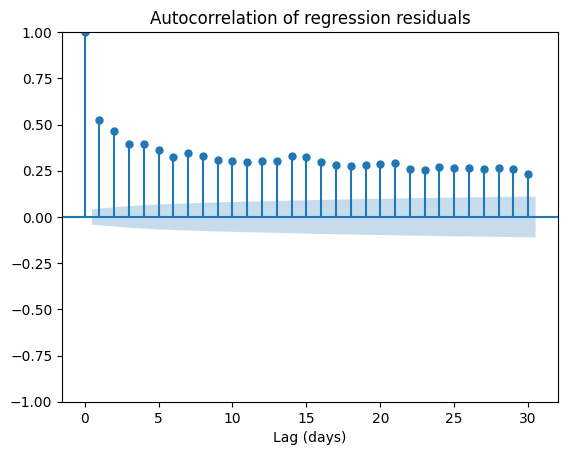

In [86]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

resid = m_full.resid

print("Residual autocorrelation at lag 1: ", round(resid.autocorr(lag=1), 2))
print("Residual autocorrelation at lag 7: ", round(resid.autocorr(lag=7), 2))
print("Residual autocorrelation at lag 30:", round(resid.autocorr(lag=30), 2))
print()
print(acorr_ljungbox(resid, lags=[7]))

plot_acf(resid, lags=30)
plt.title("Autocorrelation of regression residuals")
plt.xlabel("Lag (days)")
plt.show()

The residuals of the controlled model are still positively autocorrelated (about 0.52 at lag 1, 0.35 at lag 7 and 0.24 at lag 30), and the Ljung Box test rejects the hypothesis that they are uncorrelated. This means that the model, which uses month and year effects, does not fully capture slower changes in crime within a month. Heteroskedasticity and autocorrelation consistent (HAC) standard errors were used so that confidence intervals and p-values remain valid, but the remaining dependence is noted as a limitation of the analysis.

### Step 6: Control for yesterday's crime
Add the log of the previous day's crime count as an extra variable, to account directly for the fact that crime on one day is related to crime on the day before. The first day has no previous day, so it is dropped. Then check the temperature effect and whether the residual autocorrelation falls.

In [87]:
lag_data = daily_citywide.copy()
lag_data["Log_Crime"] = np.log(lag_data["Total_Crime"])
lag_data["Log_Crime_Yesterday"] = lag_data["Log_Crime"].shift(1)
lag_data = lag_data.dropna(subset=["Log_Crime_Yesterday"])

m_lag = smf.ols(
    "Log_Crime ~ TAVG + Log_Crime_Yesterday + C(Weekday) + C(Month) + C(Year) + Unrest_0531",
    data=lag_data
).fit(cov_type="HAC", cov_kwds={"maxlags": 7})

print("Rows used:", len(lag_data))
print("Temperature effect with yesterday's crime:", round(m_lag.params["TAVG"] * 100, 2), "% per °F")
print("95% CI:", (m_lag.conf_int().loc["TAVG"] * 100).round(2).tolist())
print("p-value:", m_lag.pvalues["TAVG"])
print("Coefficient on yesterday's crime:", round(m_lag.params["Log_Crime_Yesterday"], 2))
print()
print("Residual autocorrelation at lag 1:", round(m_lag.resid.autocorr(lag=1), 2))
print("Residual autocorrelation at lag 7:", round(m_lag.resid.autocorr(lag=7), 2))

Rows used: 2191
Temperature effect with yesterday's crime: 0.32 % per °F
95% CI: [0.27, 0.37]
p-value: 3.1752372814330695e-38
Coefficient on yesterday's crime: 0.51

Residual autocorrelation at lag 1: -0.09
Residual autocorrelation at lag 7: 0.12


Adding the previous day's crime to the model removes most of the remaining autocorrelation (residual autocorrelation at lag 1 falls from 0.52 to -0.09, and at lag 7 from 0.35 to 0.12). The temperature effect is smaller in this model, 0.32 percent per degree Fahrenheit (95 percent CI 0.27 to 0.37, p < 0.001), because yesterday's crime already carries part of the effect of persistent warm weather. Temperature therefore remains significantly associated with crime after accounting for dependence between days, but its size ranges from about 3 percent (this model) to about 6 percent (the model without yesterday's crime) per 10 degrees Fahrenheit.

### Step 7: Summary of the temperature effect across all models
Collect the temperature effect from every model into one table and chart. All models control for weekday, month, year and the May 31, 2020 flag, except the simple model.

,Model,Percent change per °F,Percent change per 10°F
0,"Simple, TAVG",0.51,5.2
1,"Controlled, TAVG",0.57,5.9
2,"Controlled, TMAX",0.48,5.0
3,"Controlled, TMIN",0.53,5.5
4,"Controlled, Poisson, TAVG",0.54,5.6
5,"Controlled + yesterday's crime, TAVG",0.32,3.3


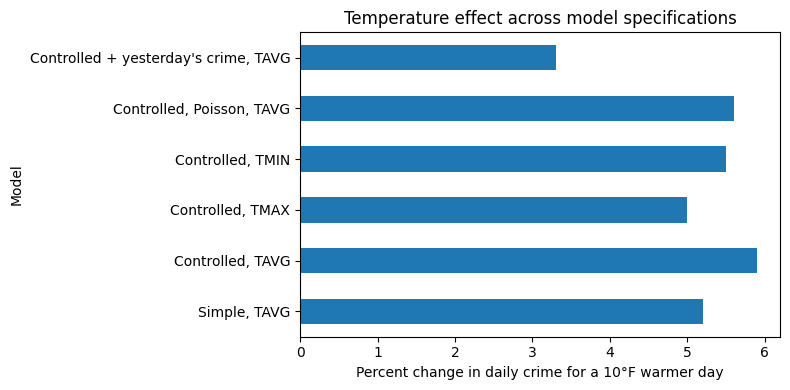

In [88]:
summary5 = robust[["Model", "Percent change per °F", "Percent change per 10°F"]].copy()

lag_row = pd.DataFrame([{
    "Model": "Controlled + yesterday's crime, TAVG",
    "Percent change per °F": round(m_lag.params["TAVG"] * 100, 2),
    "Percent change per 10°F": round((np.exp(m_lag.params["TAVG"] * 10) - 1) * 100, 1)
}])

summary5 = pd.concat([summary5, lag_row], ignore_index=True)
display(summary5)

summary5.set_index("Model")["Percent change per 10°F"].plot(kind="barh", figsize=(8, 4))
plt.xlabel("Percent change in daily crime for a 10°F warmer day")
plt.title("Temperature effect across model specifications")
plt.tight_layout()
plt.show()

Across all six specifications, temperature is positively and significantly associated with citywide crime, with estimates from about 3 percent to about 6 percent more crime for a 10 degree Fahrenheit warmer day. The association does not come from season, weekday pattern, long term trend or the May 31, 2020 outlier. The estimate is smallest when yesterday's crime is included, which accounts for dependence between days, so the size of the effect is sensitive to how that dependence is modeled even though its direction and significance are not.

## Comment 6: Connecting crime profiles, seasonality and hardship
Do neighborhoods with different crime profiles respond differently to season and temperature, and are these differences associated with socioeconomic hardship?

### Step 1: Attach monthly temperature to each community area and month
Weather is the same for every community area on a given day, so it can only explain how crime changes over time within an area. Compute the average temperature of each month, attach it to every area-month row of the panel, and add the total crime rate (the sum of the seven crime rates) and the month number.

In [89]:
monthly_temp = daily_citywide.groupby(daily_citywide["Date"].dt.to_period("M"))["TAVG"].mean()
month_temp = monthly_temp.rename("Temp").reset_index()
month_temp.columns = ["Month", "Temp"]

panel = panel.drop(columns=["Temp"], errors="ignore")
panel = panel.merge(month_temp, on="Month", how="left")
panel["Total_Rate"] = panel[crime_types].sum(axis=1)
panel["MonthNum"] = panel["Month"].dt.month

print(panel[["Community Area", "Month", "Temp", "Total_Rate", "Hardship Index"]].head())
print(panel["Temp"].isna().sum(), "missing temperatures")

   Community Area    Month       Temp  Total_Rate  Hardship Index
0               1  2020-01  30.096774    4.165615            36.5
1               1  2020-02  30.206897    3.732824            36.5
2               1  2020-03  42.806452    3.498395            36.5
3               1  2020-04  48.350000    2.560681            36.5
4               1  2020-05  59.903226    3.642659            36.5
0 missing temperatures


### Step 2: Seasonal swing by community area and its relation to hardship
For each community area, divide its average total crime rate in summer months (June to August) by its average in winter months (December to February). A ratio above 1 means more crime in summer. Then test whether this ratio is related to the Hardship Index using Spearman correlation.

count    77.000
mean      1.232
std       0.087
min       1.007
25%       1.176
50%       1.228
75%       1.292
max       1.514
Name: Summer_Winter_Ratio, dtype: float64

Spearman rho = 0.061, p = 0.5990


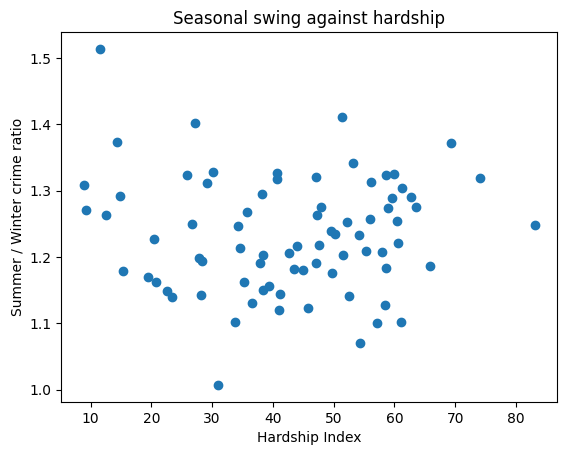

In [90]:
from scipy import stats

summer = panel[panel["MonthNum"].isin([6, 7, 8])].groupby("Community Area")["Total_Rate"].mean()
winter = panel[panel["MonthNum"].isin([12, 1, 2])].groupby("Community Area")["Total_Rate"].mean()

seasonal = (summer / winter).rename("Summer_Winter_Ratio").reset_index()
seasonal = seasonal.merge(hardship[["Community Area", "Community", "Hardship Index"]], on="Community Area")

print(seasonal["Summer_Winter_Ratio"].describe().round(3))

rho, p = stats.spearmanr(seasonal["Hardship Index"], seasonal["Summer_Winter_Ratio"])
print(f"\nSpearman rho = {rho:.3f}, p = {p:.4f}")

plt.scatter(seasonal["Hardship Index"], seasonal["Summer_Winter_Ratio"])
plt.xlabel("Hardship Index")
plt.ylabel("Summer / Winter crime ratio")
plt.title("Seasonal swing against hardship")
plt.show()

Across the 77 community areas, the summer to winter crime ratio averaged 1.23 (SD = 0.087, range 1.01 to 1.51), so every area has more crime in summer than in winter. The size of this seasonal swing was not associated with the Hardship Index (Spearman rho = 0.061, p = 0.599). Using this measure, there is no evidence that seasonal swings in crime differ between neighborhoods with different levels of socioeconomic hardship.

### Step 3: Does the seasonal swing differ across crime profiles?
Compare the summer to winter crime ratio across the three crime mix profiles, and across the three original rate based clusters. The Kruskal Wallis test checks whether the groups differ, without assuming a normal distribution.

By crime mix profile
                count  median
Mix Cluster                  
Violence heavy     35   1.252
Theft heavy        13   1.228
Mixed              29   1.206
Kruskal Wallis: H = 2.94, p = 0.2301

By original rate cluster
                count  median
Panel Cluster                
Lowest crime       39   1.183
Highest crime      13   1.273
Moderate crime     25   1.234
Kruskal Wallis: H = 9.08, p = 0.0106


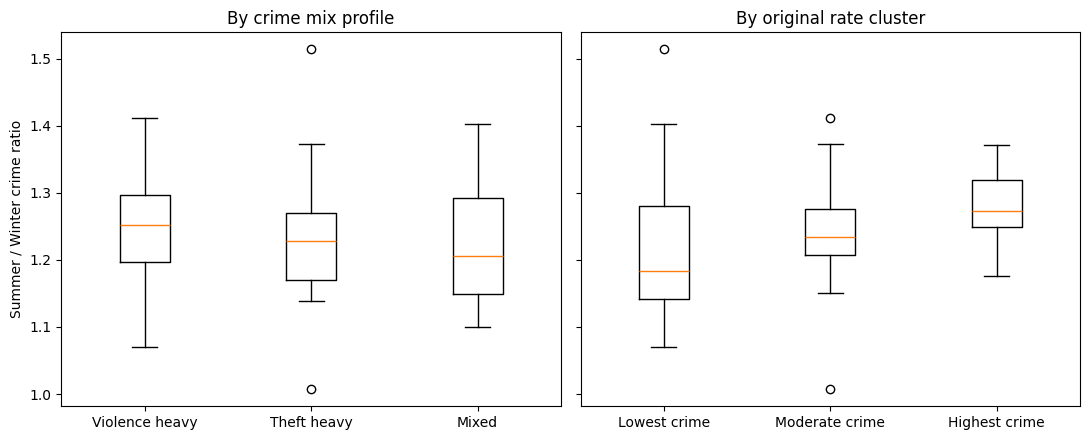

In [91]:
mix_names = {0: "Violence heavy", 1: "Theft heavy", 2: "Mixed"}
rate_names = {0: "Lowest crime", 2: "Moderate crime", 1: "Highest crime"}

seasonal = seasonal.drop(columns=["Mix Cluster", "Panel Cluster"], errors="ignore")
seasonal = seasonal.merge(features[["Community Area", "Mix Cluster"]], on="Community Area", how="left")
seasonal = seasonal.merge(overall_cluster, on="Community Area", how="left")

print("By crime mix profile")
print(seasonal.groupby("Mix Cluster")["Summer_Winter_Ratio"].agg(["count", "median"]).round(3).rename(index=mix_names))
groups = [g["Summer_Winter_Ratio"].values for _, g in seasonal.groupby("Mix Cluster")]
h, p = stats.kruskal(*groups)
print(f"Kruskal Wallis: H = {h:.2f}, p = {p:.4f}")

print("\nBy original rate cluster")
print(seasonal.groupby("Panel Cluster")["Summer_Winter_Ratio"].agg(["count", "median"]).round(3).rename(index=rate_names))
groups = [g["Summer_Winter_Ratio"].values for _, g in seasonal.groupby("Panel Cluster")]
h, p = stats.kruskal(*groups)
print(f"Kruskal Wallis: H = {h:.2f}, p = {p:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

mix_order = [0, 1, 2]
axes[0].boxplot([seasonal.loc[seasonal["Mix Cluster"] == c, "Summer_Winter_Ratio"] for c in mix_order])
axes[0].set_xticks([1, 2, 3])
axes[0].set_xticklabels([mix_names[c] for c in mix_order])
axes[0].set_title("By crime mix profile")
axes[0].set_ylabel("Summer / Winter crime ratio")

rate_order = [0, 2, 1]
axes[1].boxplot([seasonal.loc[seasonal["Panel Cluster"] == c, "Summer_Winter_Ratio"] for c in rate_order])
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels([rate_names[c] for c in rate_order])
axes[1].set_title("By original rate cluster")

plt.tight_layout()
plt.show()

The seasonal swing did not differ significantly across the crime mix profiles (Kruskal Wallis H = 2.94, p = 0.23), with median summer to winter ratios of 1.25 for the violence heavy profile, 1.23 for the theft heavy profile and 1.21 for the mixed profile. It did differ modestly across the original rate based clusters (H = 9.08, p = 0.011), with the highest crime areas showing the largest summer increase (median ratio 1.27 against 1.18 for the lowest crime areas). This suggests that seasonal variation in crime is related to how much crime an area has and not to what kind of crime it has.

### Step 4: Does the temperature effect differ by crime profile?
Fit a regression on the area-month panel of the log total crime rate on monthly temperature, profile, a temperature by profile interaction, and year. The interaction terms show how much more or less each profile responds to temperature than the reference profile (violence heavy for the mix profiles, lowest crime for the rate clusters). Standard errors are clustered by community area because repeated months within an area are not independent. Coefficients are shown in percentage points of change in crime per degree Fahrenheit.

In [92]:
panel = panel.drop(columns=["Mix_Profile", "Rate_Profile"], errors="ignore")
panel = panel.merge(
    features[["Community Area", "Mix Cluster"]].rename(columns={"Mix Cluster": "Mix_Profile"}),
    on="Community Area", how="left"
)
panel = panel.merge(
    overall_cluster.rename(columns={"Panel Cluster": "Rate_Profile"}),
    on="Community Area", how="left"
)

def interaction_table(profile_col, names):
    m = smf.ols(
        f"np.log(Total_Rate) ~ Temp * C({profile_col}) + C(Year)",
        data=panel
    ).fit(cov_type="cluster", cov_kwds={"groups": panel["Community Area"]})

    rows = [("Temperature effect, reference profile", m.params["Temp"] * 100, m.pvalues["Temp"])]
    for key in m.params.index:
        if key.startswith("Temp:"):
            level = int(key.split("T.")[1].rstrip("]"))
            rows.append((f"Extra effect for {names[level]}", m.params[key] * 100, m.pvalues[key]))

    out = pd.DataFrame(rows, columns=["Term", "Percentage points per °F", "p-value"])
    out["Percentage points per °F"] = out["Percentage points per °F"].round(3)
    out["p-value"] = out["p-value"].round(3)
    return out

print("Crime mix profiles (reference: Violence heavy)")
display(interaction_table("Mix_Profile", mix_names))

print("Original rate clusters (reference: Lowest crime)")
display(interaction_table("Rate_Profile", rate_names))

Crime mix profiles (reference: Violence heavy)


,Term,Percentage points per °F,p-value
0,"Temperature effect, reference profile",0.527,0.000
1,Extra effect for Theft heavy,-0.004,0.946
2,Extra effect for Mixed,-0.037,0.228


Original rate clusters (reference: Lowest crime)


,Term,Percentage points per °F,p-value
0,"Temperature effect, reference profile",0.491,0.000
1,Extra effect for Highest crime,0.064,0.063
2,Extra effect for Moderate crime,0.034,0.357


In a panel regression with a temperature by profile interaction and standard errors clustered by community area, monthly temperature was associated with about 0.5 percent more crime per degree Fahrenheit in every profile. The interaction terms for the crime mix profiles were small and not significant (theft heavy -0.004 points, p = 0.946; mixed -0.037 points, p = 0.228), so crime mix profiles do not differ in their response to temperature. For the original rate based clusters, the highest crime group showed a slightly larger response (+0.064 points per degree, p = 0.063), which is suggestive but not statistically significant at the 0.05 level.

### Step 5: Temperature effect for each community area
For each community area, fit a separate Poisson regression of daily crime counts on temperature, controlling for weekday and for year and month. Days with no recorded crime in an area are filled with zero. The coefficient is converted to the percent change in crime for a 10 degree Fahrenheit warmer day. Areas with fewer than one crime per day on average are excluded, because their estimates are too noisy. Then compare the area effects with hardship and with the crime mix profiles.

Areas used: 73 of 77
Median effect: 4.8 % per 10°F
Middle half of areas: [3.7, 6.1]

Hardship vs temperature effect: Spearman rho = 0.35, p = 0.0022
Violence to theft log ratio vs temperature effect: Spearman rho = 0.42, p = 0.0002

By crime mix profile
                count  median
Mix Cluster                  
Violence heavy     34     5.4
Theft heavy        13     4.6
Mixed              26     4.1
Kruskal Wallis: H = 8.92, p = 0.0116


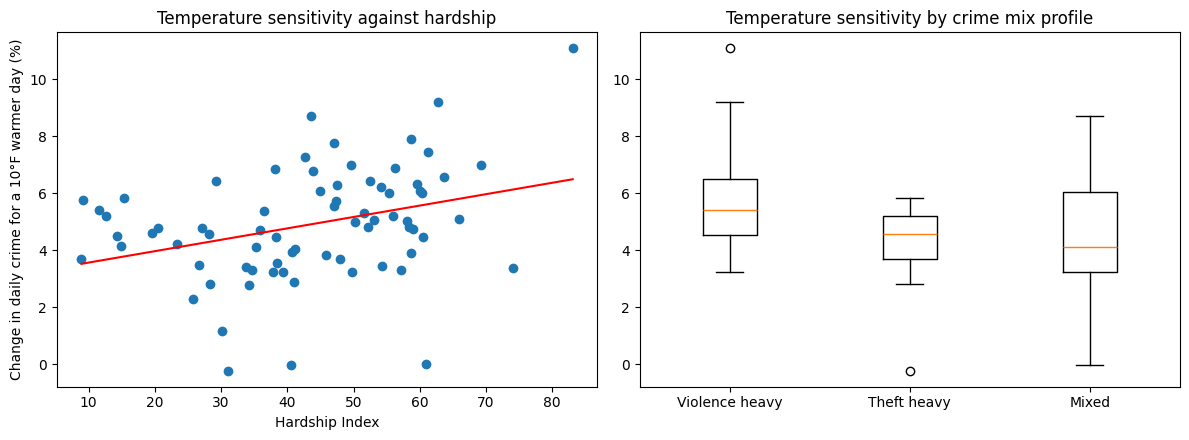

In [93]:
import statsmodels.api as sm

area_day = crime.groupby(["Community Area", "Date"]).size().rename("n").reset_index()

dates = daily_citywide[["Date", "TAVG"]].copy()
dates["YearMonth"] = dates["Date"].dt.to_period("M").astype(str)
dates["Weekday"] = dates["Date"].dt.dayofweek
dates["Temp10"] = dates["TAVG"] / 10

rows = []
for area, g in area_day.groupby("Community Area"):
    d = dates.merge(g[["Date", "n"]], on="Date", how="left").fillna({"n": 0})
    m = smf.glm(
        "n ~ Temp10 + C(Weekday) + C(YearMonth)",
        data=d, family=sm.families.Poisson()
    ).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    rows.append((area, m.params["Temp10"], m.bse["Temp10"], d["n"].mean()))

area_slopes = pd.DataFrame(rows, columns=["Community Area", "coef", "se", "mean_daily_crimes"])
area_slopes["Percent per 10F"] = (np.exp(area_slopes["coef"]) - 1) * 100
area_slopes = area_slopes.merge(
    features[["Community Area", "Hardship Index", "Mix Cluster", "Log Violence/Theft"]],
    on="Community Area"
)

used = area_slopes[area_slopes["mean_daily_crimes"] >= 1]

print("Areas used:", len(used), "of", len(area_slopes))
print("Median effect:", round(used["Percent per 10F"].median(), 1), "% per 10°F")
print("Middle half of areas:", used["Percent per 10F"].quantile([0.25, 0.75]).round(1).tolist())

rho, p = stats.spearmanr(used["Hardship Index"], used["Percent per 10F"])
print(f"\nHardship vs temperature effect: Spearman rho = {rho:.2f}, p = {p:.4f}")
rho, p = stats.spearmanr(used["Log Violence/Theft"], used["Percent per 10F"])
print(f"Violence to theft log ratio vs temperature effect: Spearman rho = {rho:.2f}, p = {p:.4f}")

print("\nBy crime mix profile")
print(used.groupby("Mix Cluster")["Percent per 10F"].agg(["count", "median"]).round(1).rename(index=mix_names))
groups = [g["Percent per 10F"].values for _, g in used.groupby("Mix Cluster")]
h, p = stats.kruskal(*groups)
print(f"Kruskal Wallis: H = {h:.2f}, p = {p:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(used["Hardship Index"], used["Percent per 10F"])
z = np.polyfit(used["Hardship Index"], used["Percent per 10F"], 1)
xs = np.linspace(used["Hardship Index"].min(), used["Hardship Index"].max(), 50)
axes[0].plot(xs, np.polyval(z, xs), color="red")
axes[0].set_xlabel("Hardship Index")
axes[0].set_ylabel("Change in daily crime for a 10°F warmer day (%)")
axes[0].set_title("Temperature sensitivity against hardship")

data = [used.loc[used["Mix Cluster"] == c, "Percent per 10F"] for c in [0, 1, 2]]
axes[1].boxplot(data)
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels([mix_names[c] for c in [0, 1, 2]])
axes[1].set_title("Temperature sensitivity by crime mix profile")

plt.tight_layout()
plt.show()

Estimating the temperature effect separately for each community area, using daily counts with zero filled days and controls for weekday and year-month, the median area showed a 4.8 percent increase in crime for a 10 degree Fahrenheit warmer day (middle half 3.7 to 6.1 percent; 73 of 77 areas with at least one crime per day). Areas with higher hardship were somewhat more sensitive to temperature (Spearman rho = 0.35, p = 0.002), as were areas with a more violent crime mix (rho = 0.42, p < 0.001). The temperature effect differed across the crime mix profiles (Kruskal Wallis H = 8.92, p = 0.012), with a median of 5.4 percent for the violence heavy profile, 4.6 percent for the theft heavy profile and 4.1 percent for the mixed profile. In contrast, the seasonal summer to winter ratio and the temperature by profile regression showed no significant difference between the mix profiles. The profiles therefore have similar seasonal swings, but violence heavy areas respond slightly more to warmer days within a month. These differences are small and are associations, not evidence of cause.

### Step 6: Summary of comment 6

| Question | Measure | Result |
|---|---|---|
| Does the seasonal swing relate to hardship? | Summer to winter ratio, Spearman | rho = 0.061, p = 0.599 (no relationship) |
| Does the seasonal swing differ across crime mix profiles? | Kruskal Wallis | H = 2.94, p = 0.230 (no difference) |
| Does the seasonal swing differ across rate based clusters? | Kruskal Wallis | H = 9.08, p = 0.011 (small difference) |
| Does the temperature effect differ by crime mix profile? | Panel regression, interaction | p = 0.946 and 0.228 (no difference) |
| Does the temperature effect differ by rate based cluster? | Panel regression, interaction | highest crime +0.064 points per °F, p = 0.063 (suggestive) |
| Is each area's temperature effect related to hardship? | Daily Poisson models, Spearman | rho = 0.35, p = 0.002 (modest relationship) |
| Does each area's temperature effect differ by crime mix profile? | Daily Poisson models, Kruskal Wallis | H = 8.92, p = 0.012 (small difference) |

Seasonal swings (summer against winter) are similar across crime mix profiles and unrelated to hardship. Temperature sensitivity within a month is slightly higher in areas with more hardship and a more violent crime mix, with medians of 5.4 percent per 10 degrees Fahrenheit for violence heavy areas against 4.1 percent for mixed areas. All of these differences are small, and they are associations between areas, not evidence that hardship causes a different response to weather.

In [94]:
# 1. Agreement between the original groups and the total rate groups
def label_names(col):
    order = panel.groupby(col)["Total Rate"].mean().sort_values().index
    return dict(zip(order, ["lowest", "moderate", "highest"]))
a = panel["Panel Cluster"].map(label_names("Panel Cluster"))
b = panel["Total Rate Cluster"].map(label_names("Total Rate Cluster"))
print("Rows in the same group in both runs (%):", round((a == b).mean() * 100, 1))

# 2. Which area moved through all three groups
path = panel.groupby(["Community Area", "Year"])["Panel Cluster"].agg(lambda x: x.mode()[0]).unstack()
print(hardship.loc[hardship["Community Area"].isin([36, 37]), ["Community Area", "Community"]])
print(path.loc[[36, 37]])
print("Areas with three groups:", path.nunique(axis=1).eq(3).loc[lambda s: s].index.tolist())
oak = panel[panel["Community Area"] == 36].set_index("Month")["MOTOR VEHICLE THEFT"].round(2)
print(oak["2022-10":"2023-06"])
print("First 12 months:", round(oak.iloc[:12].mean(), 2), "Last 12 months:", round(oak.iloc[-12:].mean(), 2))

# 3. Typical day
print("Average crimes per day:", round(len(crime) / daily_citywide.shape[0], 1))

Rows in the same group in both runs (%): 93.6
    Community Area    Community
35              36      Oakland
36              37  Fuller Park
Year            2020  2021  2022  2023  2024  2025
Community Area                                    
36                 0     2     2     1     2     2
37                 1     1     1     1     1     1
Areas with three groups: [36]
Month
2022-10    1.91
2022-11    2.79
2022-12    3.53
2023-01    3.23
2023-02    2.20
2023-03    2.79
2023-04    4.26
2023-05    2.79
2023-06    2.35
Freq: M, Name: MOTOR VEHICLE THEFT, dtype: float64
First 12 months: 0.34 Last 12 months: 1.44
Average crimes per day: 485.9
